# Example II · Stochastic gradient descent — Figure 2와 Theorem 5

[공통 분석 흐름](00_Common_analysis_pipeline.ipynb)의 다섯 단계를 SGD에 적용한다. [Example I의 GD](3_2_1_Figure_1_1A_GradientDescent.ipynb)에서 사용한 **Gram 표현·interpolation 부등식·LMI 구성과 수치 탐색 → 단순화 → 증명의 흐름**을 그대로 이어간다.

SGD에서는 조건부 기대값, 분산 행렬 $A_{\mathrm{var}}$, 오차 계수 $e_k$를 추가한다. 최적화에서는 $d_N$ 최대화 후, $\sum_{k<N}e_k$를 최소화한다.

| 공통 단계 | 분석 대상 | 결과 |
| --- | --- | --- |
| 1단계 · 알고리즘과 가정 | 확률적 gradient에 어떤 조건을 두는가? | SGD 업데이트, 조건부 불편성과 분산 상한 |
| 2단계 · Parameterized potential 설정 | 마지막 반복점에서 함수값의 기대값 상한을 구하려면 어떤 항과 경계조건이 필요한가? | $a_k,b_k,c_k,d_k$와 오차 계수 $e_k$, 초기·최종 potential의 역할 |
| 3단계 · LMI/SDP로 계수 수치 탐색 | GD의 행렬 조건에 기대값과 분산을 어떻게 반영하는가? | Interpolation 부등식과 분산 제약으로 구성한 LMI와 두 최적화 문제의 수치해 |
| 4단계 · 계수 패턴 관찰과 단순화 | 계수를 제한해도 어떤 구조와 상한이 남는가? | Figure 2의 비교와 $a_k=L/2$, $b_k=c_k=0$인 potential 후보 |
| 5단계 · 해석적 potential inequality와 수렴률 | 후보의 계수를 명시하고 potential 부등식을 모든 반복에서 증명할 수 있는가? | Theorem 5의 점화식, potential inequality, telescoping으로 얻은 함수값 상한 |

[논문 §3.2.2, Figure 2, Appendix E.1·E.7](https://proceedings.mlr.press/v99/taylor19a.html) · [참조 Python 코드](../2_Stochastic_BoundedVariance/A_StochasticGradientDescent.py) · [수식·코드 대응 정리](../docs/3_2_2_Figure_2_2A_StochasticGradientDescent.md)


## 1단계 · 알고리즘과 가정

$f\in\mathcal F_L$로 둔다. $x_\star$는 최적점이다. $f_\star=f(x_\star)$로 쓴다. 현재 점에서 확률적 gradient를 반환하는 oracle은

$$\mathbb E_i[G(x_k;i)]=f'(x_k),\qquad
\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2\le\sigma^2$$

를 만족한다고 가정한다. 여기서는 현재 $x_k$까지의 정보를 조건으로 하는 **조건부 기대값**을 사용한다. 수치 실험에서는 $i\in\{1,\ldots,n\}$을 균등하게 선택하고

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad \delta_k=1/L$$

로 업데이트한다. 이 예제에서는 마지막 반복점 $x_N$에서의 함수값을 분석한다. GD에서는 정확한 gradient로 다음 점 하나가 정해졌지만, 여기서는 oracle 결과에 따라 다음 점이 달라진다.

## 2단계 · Parameterized potential 설정

알고리즘과 가정을 정했으므로, 이제 한 단계 업데이트 전후의 변화를 분석할 potential의 형태를 선택한다. GD에서 사용한 거리·gradient·교차항·함수값의 네 항을 그대로 두고 계수를 탐색한다.

$$\boxed{\phi_k^f(x)=a_k\|x-x_\star\|^2+b_k\|f'(x)\|^2
+2c_k\langle f'(x),x-x_\star\rangle+d_k(f(x)-f_\star).}$$

다만 이번에는 확률적 gradient의 오차를 고려해야 하므로, GD의 $\phi_{k+1}^f\le\phi_k^f$ 대신 다음 부등식을 요구한다.

$$\boxed{\mathbb E_i[\phi_{k+1}^f(x_{k+1}^{(i)})]\le\phi_k^f(x_k)+e_k\sigma^2,\qquad e_k\ge0.}$$

$a_k,b_k,c_k,d_k$는 $k=0,\ldots,N$에서 정의하는 potential 계수이고, $e_k$는 한 단계 업데이트 $k\to k+1$에서 허용하는 오차의 계수다. 따라서 $e_k$의 인덱스는 $k=0,\ldots,N-1$이다.

이차항의 계수는 $Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$로 모아 쓴다. 중간 potential의 계수에는 별도의 부호 조건을 두지 않으며, $Q_k\succeq0$도 요구하지 않는다.

**SDP의 목적함수는 경계조건 $\phi_0^f,\phi_N^f$에서 결정된다.** 기본 설정에서는 $\phi_0^f=\frac L2\|x_0-x_\star\|^2$, $\phi_N^f=d_N(f(x_N)-f_\star)$로 둔다. 한 단계 부등식의 합으로 얻는 상한은 $d_N$과 $\sum_{k<N}e_k$에 의존한다. 이에 따라 $d_N$ 최대화 후 그 값을 거의 유지하면서 $\sum e_k$를 최소화한다. 정확한 목적함수와 LMI는 3단계에서 구성한다.


In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util

import cvxpy as cp
import matplotlib.pyplot as plt
import mosek
import numpy as np
from IPython.display import Markdown, display

repo_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "2_Stochastic_BoundedVariance/A_StochasticGradientDescent.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from the repository root or its ipynb directory.")
license_path = repo_root / "mosek.lic"
if license_path.is_file():
    mosek.Env().putlicensepath(str(license_path))

adapter_path = repo_root / "2_Stochastic_BoundedVariance/saveData.py"
spec = importlib.util.spec_from_file_location("sgd_saveData", adapter_path)
solver_adapter = importlib.util.module_from_spec(spec)
spec.loader.exec_module(solver_adapter)
solve = solver_adapter.solve

### 이번 수치 탐색의 설정

먼저 Figure 2의 기본 설정에서 중간 potential의 계수를 자유롭게 탐색한다.

$$L=1,\quad \texttt{m}=0,\quad N=100,\quad n=2,\quad \delta_k=1/L,\quad \mathrm{relax}=0.$$

코드의 강한 볼록성 계수 `m=0`인 smooth convex 문제를 다룬다. `relax=0`은 중간 계수에 추가적인 제한을 두지 않는 설정이다.


In [2]:
solver = "MOSEK"
tolerance = 1e-8
tol_reopt = 1e-5
verbose = False
L = 1.0
m = 0.0
n = 2
N_FIGURE = 100
N = N_FIGURE
relax = 0

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 11,
})
print(f"CVXPY {cp.__version__} | MOSEK {'.'.join(map(str, mosek.Env.getversion()))}")
print(f"L={L:g}, mu={m:g}, N={N}, n={n}, relax={relax}, solver={solver}")

CVXPY 1.9.3 | MOSEK 11.2.6
L=1, mu=0, N=100, n=2, relax=0, solver=MOSEK


## 3단계 · LMI/SDP로 계수 수치 탐색

2단계에서 고른 potential과 경계조건을 만족시키는 계수를 찾는다. 가능한 점·gradient·함수값을 Gram 행렬과 함수값 벡터로 나타내고, potential 부등식을 계수에 대한 유한차원 행렬 조건으로 바꾼다. SGD에서는 다음 potential을 oracle 결과에 대해 평균 내고, 분산 상한도 interpolation 부등식과 함께 반영한다.

### 한 단계의 Gram 표현: Appendix E.7의 표기

좌표의 원점과 함수값의 기준을 옮겨 $x_\star=f_\star=0$으로 둔다. 최적점에서는 $f'(x_\star)=0$이다. 논문과 같이

$$P=[\,x_k\quad G(x_k;1)\ \cdots\ G(x_k;n)\quad
f'(x_{k+1}^{(1)})\ \cdots\ f'(x_{k+1}^{(n)})\,],\qquad
G=P^\top P\succeq0,$$
$$F=[\,f(x_k)\quad f(x_{k+1}^{(1)})\ \cdots\ f(x_{k+1}^{(n)})\,]
\in\mathbb R^{1\times(n+1)}$$

로 쓴다. 단독으로 쓰는 $G$는 Gram 행렬이고, $G(x_k;i)$는 확률적 gradient다.

논문 Appendix E.7의 굵은 기호 $\mathbf x_p,\mathbf g_p,\mathbf f_p,\mathbf G_i$는 실제 벡터와 함수값을 선택하는 계수벡터다. 한 전이에서 현재 점의 번호는 $0$, 다음 점의 번호는 $i=1,\ldots,n$이다. 예를 들어 $P\mathbf x_0=x_k$, $P\mathbf g_0=f'(x_k)$, $F\mathbf f_0=f(x_k)$, $P\mathbf G_i=G(x_k;i)$다. $n=2$에서는 다음과 같다.

$$\begin{array}{c|cccc}
p&\star&0&1&2\\\hline
\mathbf x_p&0&\mathbf e_1&\mathbf e_1-\delta_k\mathbf e_2&\mathbf e_1-\delta_k\mathbf e_3\\
\mathbf g_p&0&(\mathbf e_2+\mathbf e_3)/2&\mathbf e_4&\mathbf e_5\\
\mathbf f_p&0&(1,0,0)^\top&(0,1,0)^\top&(0,0,1)^\top
\end{array}$$

$\mathbf e_j$는 해당 공간의 $j$번째 표준기저벡터다. Oracle의 계수벡터는 $\mathbf G_1=\mathbf e_2$, $\mathbf G_2=\mathbf e_3$이고, 일반적으로

$$\mathbf g_0=\frac1n\sum_{i=1}^n\mathbf G_i,\qquad
\mathbf x_i=\mathbf x_0-\delta_k\mathbf G_i$$

로 두어 불편성과 업데이트를 반영한다. Potential의 이차항 행렬도 논문 표기를 그대로 쓴다.

$$\begin{aligned}
V_k&=[\mathbf x_0-\mathbf x_\star\ \mathbf g_0]\,
Q_k[\mathbf x_0-\mathbf x_\star\ \mathbf g_0]^\top,\\
V_{k+1}^{(i)}&=[\mathbf x_i-\mathbf x_\star\ \mathbf g_i]\,
Q_{k+1}[\mathbf x_i-\mathbf x_\star\ \mathbf g_i]^\top.
\end{aligned}$$

따라서 기대 potential 차이는

$$\mathbb E_i[\phi_{k+1}^f]-\phi_k^f
=\operatorname{Tr}\!\left[G\left(\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k\right)\right]
+F\left[\frac{d_{k+1}}n\sum_{i=1}^n\mathbf f_i-d_k\mathbf f_0\right]$$

이다. 구현에서는 이 표현에서 얻는 쌍대 LMI를 풀므로 Gram 행렬을 CVXPY 변수로 선언하지 않는다. 아래 코드의 딕셔너리 `G`는 각 점의 gradient 계수벡터를 저장한다.


In [3]:
dimG = 1 + 2 * n
dimF = n + 1
nbPts = n + 2

xk = np.zeros(dimG)
xk[0] = 1
xs = np.zeros(dimG)
Gxk = np.zeros((n, dimG))
Gxk[:, 1:n + 1] = np.eye(n)
gxk = Gxk.mean(axis=0)  # Unbiasedness: gxk averages the stochastic-gradient coefficient vectors.
gxk1 = np.zeros((n, dimG))
gxk1[:, n + 1:2 * n + 1] = np.eye(n)
gxs = np.zeros(dimG)

fxk = np.zeros(dimF)
fxk[0] = 1
fxk1 = np.zeros((n, dimF))
fxk1[:, 1:n + 1] = np.eye(n)
fxs = np.zeros(dimF)

# delta_k = 1/L is constant in every experiment in this notebook.
XK1 = np.tile(xk, (n, 1)) - Gxk / L
X = {1: xs, 2: xk}
G = {1: gxs, 2: gxk}
F = {1: fxs, 2: fxk}
for i in range(1, n + 1):
    X[2+i], G[2+i], F[2+i] = XK1[i - 1], gxk1[i - 1], fxk1[i - 1]
statesKG = np.column_stack((xk - xs, gxk))
print(f"Gram dimension={dimG}, function-value dimension={dimF}, points={nbPts}")

Gram dimension=5, function-value dimension=3, points=4


### Interpolation 부등식과 분산 행렬

논문 Appendix E.7의 점 집합은 $I=\{\star,0,1,\ldots,n\}$이다. 모든 점의 함수값과 gradient는 하나의 smooth convex 함수에서 얻으므로, 서로 다른 두 점의 순서를 구분해 interpolation 부등식을 적용한다.

$$f(x_p)-f(x_q)-\langle f'(x_q),x_p-x_q\rangle
-\frac1{2L}\|f'(x_p)-f'(x_q)\|^2\ge0.$$

여기서 $p=0$은 현재 점 $x_k$, $p=i$는 다음 점 $x_{k+1}^{(i)}$를 가리킨다. 부등식은 일반적인 $n$에서 $(n+2)(n+1)$개이고, $n=2$에서는 12개다. 행렬로 옮기면

$$M=\frac12\begin{pmatrix}
0&0&0&-1\\0&0&0&1\\0&0&-1/L&1/L\\-1&1&1/L&-1/L
\end{pmatrix},$$
$$M_{p,q}=[\mathbf x_p\ \mathbf x_q\ \mathbf g_p\ \mathbf g_q]\,
M[\mathbf x_p\ \mathbf x_q\ \mathbf g_p\ \mathbf g_q]^\top$$

이며, 각 interpolation 부등식은

$$F(\mathbf f_p-\mathbf f_q)+\operatorname{Tr}(GM_{p,q})\ge0$$

가 된다. 분산 상한도 논문의 $A_{\mathrm{var}}$로 표현한다.

$$A_{\mathrm{var}}=\frac1n\sum_{i=1}^n(\mathbf G_i-\mathbf g_0)(\mathbf G_i-\mathbf g_0)^\top,\qquad
\operatorname{Tr}(GA_{\mathrm{var}})=\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2\le\sigma^2.$$

$n=2$에서는 $A_{\mathrm{var}}=(\mathbf e_2-\mathbf e_3)(\mathbf e_2-\mathbf e_3)^\top/4$이다. 아래 코드의 `TT`는 $[\mathbf x_p\ \mathbf x_q\ \mathbf g_p\ \mathbf g_q]^\top$이므로, `TT.T @ M @ TT`가 $M_{p,q}$에 해당한다.


In [4]:
# The general smooth strongly convex formula reduces to the displayed M at m=0.
M = np.array([
    [-L*m, L*m, m, -L],
    [L*m, -L*m, -m, L],
    [m, -m, -1, 1],
    [-L, L, 1, -1],
]) / (2 * (L - m))
Avar = np.zeros((dimG, dimG))
for i in range(n):
    Avar += np.outer(Gxk[i] - gxk, Gxk[i] - gxk) / n

interp_M, interp_F = {}, {}
for i in range(1, nbPts + 1):
    for j in range(1, nbPts + 1):
        if i != j:
            TT = np.vstack((X[i], X[j], G[i], G[j]))  # Rows select the two points and their gradients.
            interp_M[i, j] = TT.T @ M @ TT
            interp_F[i, j] = F[i] - F[j]
print(f"Ordered interpolation pairs: {len(interp_M)}")
print("Avar =")
print(Avar)

Ordered interpolation pairs: 12
Avar =
[[ 0.    0.    0.    0.    0.  ]
 [ 0.    0.25 -0.25  0.    0.  ]
 [ 0.   -0.25  0.25  0.    0.  ]
 [ 0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.  ]]


### 경계조건 $\phi_0^f,\phi_N^f$와 두 단계 최적화

2단계에서 선택한 초기·최종 potential을 식으로 쓰면 다음과 같다. 논문 식 (4)의 기본 경계조건이다.

$$\phi_0^f=\frac L2\|x_0-x_\star\|^2,\qquad
\phi_N^f=d_N(f(x_N)-f_\star).$$

각 단계의 조건부 기대값 부등식에 다시 기대값을 취하고 합하면

$$d_N\mathbb E[f(x_N)-f_\star]
\le\frac L2\|x_0-x_\star\|^2+\sigma^2\sum_{k=0}^{N-1}e_k$$

를 얻는다. 따라서 $d_N>0$이면

$$\boxed{\mathbb E[f(x_N)-f_\star]\le
\underbrace{\frac{L}{2d_N}}_{\text{초기 거리항의 계수}}\|x_0-x_\star\|^2
+\underbrace{\frac{\sum_{k=0}^{N-1}e_k}{d_N}}_{\text{분산 항의 계수}}\sigma^2.}$$

이 식에서 두 목적함수의 역할이 드러난다. **먼저 $d_N$을 최대화해 초기 거리항의 계수를 줄이고, 그 값을 거의 유지하면서 $\sum e_k$를 최소화해 분산 항을 줄인다.** GD에서는 $b_N$ 하나를 최대화했지만, 여기서는 두 목적함수를 차례로 최적화한다. 이는 초기 거리와 $\sigma^2$를 특정 값으로 고정해 전체 상한을 한꺼번에 최소화하는 것과는 구별된다.


In [5]:
t_start = perf_counter()
tau = cp.Variable(name="tau")  # tau = d_N.
Q0 = np.array([[L / 2, 0.0], [0.0, 0.0]])
QN = np.zeros((2, 2))
Q = {1: Q0, N + 1: QN}
d = {1: 0.0, N + 1: tau}

### 중간 potential의 미지수와 코드 인덱스

초기·최종 potential 사이의 계수는 다음과 같이 둔다.

$$Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}\in\mathbb S^2,\qquad
d_k\in\mathbb R\quad(1\le k<N).$$

`Q`와 `d`는 참조 Python 코드처럼 **정수 키가 1부터 시작하는 딕셔너리**다. 수식에서 상태 $k$의 계수는 `Q[k+1]`, `d[k+1]`에, 업데이트 $k\to k+1$에 대한 계수는 `lam[k+1]`, `e[k+1]`에 대응한다. 계산 후 추출하는 NumPy 배열은 수식과 같이 0부터 시작한다.

`lam[k]`는 $(n+2)\times(n+2)$ 행렬이다. 한 점을 자기 자신과 비교하는 interpolation 부등식은 사용하지 않으므로 대각 원소는 합에 들어가지 않는다. 아래에서는 미지수를 선언하고, $e_k\ge0$과 $\lambda_{p,q}\ge0$은 LMI를 등록할 때 함께 추가한다. $Q_k$에는 대칭성만 요구하며, $Q_k\succeq0$는 추가하지 않는다.


In [6]:
lam, e = {}, {}
for k in range(1, N + 1):
    if k < N:
        d[k + 1] = cp.Variable(name=f"d_{k + 1}")
        Q[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
    lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")
    e[k] = cp.Variable(name=f"e_{k}")

### 비음수 가중합에서 분산 행렬항이 나오는 이유

보이고 싶은 부등식의 좌변은 $\mathbb E_i[\phi_{k+1}^f]-\phi_k^f-e_k\sigma^2$이다. Interpolation 부등식과 분산 상한에서 얻은 비음수 항을 더한다. 분산 부등식의 multiplier는 오차 계수와 같은 $e_k$로 선택한다.

$$\begin{aligned}
&\mathbb E_i[\phi_{k+1}^f]-\phi_k^f-e_k\sigma^2
+\sum_{p,q\in I}\lambda_{p,q}\left[F(\mathbf f_p-\mathbf f_q)+\operatorname{Tr}(GM_{p,q})\right]\\
&\qquad+e_k\left[\sigma^2-\operatorname{Tr}(GA_{\mathrm{var}})\right]\\
&=\mathbb E_i[\phi_{k+1}^f]-\phi_k^f
+\sum_{p,q\in I}\lambda_{p,q}\left[F(\mathbf f_p-\mathbf f_q)+\operatorname{Tr}(GM_{p,q})\right]
-e_k\operatorname{Tr}(GA_{\mathrm{var}}).
\end{aligned}$$

두 $\sigma^2$ 항이 소거되면서, GD의 행렬 조건에 $-e_kA_{\mathrm{var}}$가 추가된다. 이 식 전체가 0 이하이면, 비음수 항을 더하기 전의 식도 0 이하가 된다.

먼저 아래 코드는 interpolation 항을 더하기 전의 두 표현

$$\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k-e_kA_{\mathrm{var}},\qquad
\frac{d_{k+1}}n\sum_{i=1}^n\mathbf f_i-d_k\mathbf f_0$$

을 각각 `cons_SDP[k]`, `cons_LIN[k]`에 구성한다. 상태와 업데이트의 코드 인덱스는 앞의 대응표를 따른다.


In [7]:
cons_SDP, cons_LIN = {}, {}
for k in range(1, N + 1):
    cons_SDP[k] = -statesKG @ Q[k] @ statesKG.T - e[k] * Avar
    cons_LIN[k] = -d[k] * fxk
    for i in range(n):
        statesK1G = np.column_stack((XK1[i] - xs, gxk1[i]))
        cons_SDP[k] = cons_SDP[k] + statesK1G @ Q[k + 1] @ statesK1G.T / n
        cons_LIN[k] = cons_LIN[k] + d[k + 1] * fxk1[i] / n

### 함수값 계수의 소거와 LMI

앞의 가중합을 trace 항과 함수값 항으로 모으면

$$\begin{aligned}
&\operatorname{Tr}\!\left[G\left(\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k-e_kA_{\mathrm{var}}
+\sum_{p,q\in I}\lambda_{p,q}M_{p,q}\right)\right]\\
&\quad+F\left[\frac{d_{k+1}}n\sum_{i=1}^n\mathbf f_i-d_k\mathbf f_0
+\sum_{p,q\in I}\lambda_{p,q}(\mathbf f_p-\mathbf f_q)\right]
\end{aligned}$$

이다. 모든 $G\succeq0,F$에 대해 이 식이 0 이하가 되도록 다음 조건을 둔다. 논문 Appendix E.7의 표기다.

$$\boxed{\begin{aligned}
\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k-e_kA_{\mathrm{var}}
+\sum_{p,q\in I}\lambda_{p,q}M_{p,q}&\preceq0,\\
\frac{d_{k+1}}n\sum_{i=1}^n(\mathbf f_i-\mathbf f_\star)-d_k(\mathbf f_0-\mathbf f_\star)
+\sum_{p,q\in I}\lambda_{p,q}(\mathbf f_p-\mathbf f_q)&=0,\\
\lambda_{p,q}\ge0,\qquad e_k&\ge0.
\end{aligned}}$$

업데이트와 $L$을 고정했으므로 $V_k,V_{k+1}^{(i)}$는 $Q_k,Q_{k+1}$의 성분에 선형이고, $A_{\mathrm{var}},M_{p,q}$는 상수행렬이다. 따라서 LMI 좌변의 성분은 potential 계수와 multiplier에 대해 affine하다.

한 문제에 $N$개의 $(1+2n)\times(1+2n)$ LMI와 $(n+1)N$개의 스칼라 등식이 들어간다. 코드의 점 번호 $1,2,3,\ldots,n+2$는 논문의 $\star,0,1,\ldots,n$에 순서대로 대응한다. 아래에서는 대각을 제외한 12개 점 쌍의 interpolation 항을 더한다.


In [8]:
for k in range(1, N + 1):
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if i != j:
                cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * interp_M[i, j]
                cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * interp_F[i, j]

### 행렬 조건을 CVXPY 제약으로 등록하기

앞에서 구성한 LMI 좌변은 코드의 `cons_SDP[k]`에, 함수값 계수벡터는 `cons_LIN[k]`에 들어 있다. 각각 `cons_SDP[k] << 0`, `cons_LIN[k] == 0`으로 등록하고, multiplier 조건 `lam[k] >= 0`, `e[k] >= 0`과 최종 계수 조건 `tau >= 0`도 추가한다.

기본 실험에서는 전체 $(1+2n)\times(1+2n)$ LMI를 사용한다. 뒤의 `relax=3`에서는 이 LMI와 동치인 조건으로 행렬의 크기를 줄인다.


In [9]:
cons = [tau >= 0]
for k in range(1, N + 1):
    cons += [cons_SDP[k] << 0, cons_LIN[k] == 0, lam[k] >= 0, e[k] >= 0]
accumulated_ek = sum(e.values())
print(f"{N} full {dimG} x {dimG} LMIs, {N * dimF} function-value equalities")

100 full 5 x 5 LMIs, 300 function-value equalities


### 목적함수를 바꾸어 두 차례 최적화하기

먼저 $N=100$에서 최종 potential의 함수값 계수를 최대화한다.

$$d_N^{\mathrm{opt}}=\max\{\tau:\text{앞에서 구성한 모든 제약}\}.$$

코드의 `Minimize(-tau)`는 이 최댓값을 구하는 목적함수다. 첫 번째 최적화에서는 제약을 만족하는지 판단할 MOSEK의 허용오차를 $10^{-8}$로 설정한다.


In [10]:
solver_opt = {
    "solver": solver, "verbose": verbose,
    "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance},
}
problem = cp.Problem(cp.Minimize(-tau), cons)
solve(problem, **solver_opt)
if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
    raise RuntimeError(f"Stage 1 failed: {problem.status}")
print(f"Stage 1: status={problem.status}, d_N={tau.value:.10g}")

Stage 1: status=optimal, d_N=201.0000089


#### 첫 번째 최적화의 계수를 보관하기

$Q_k$의 성분에서 potential 계수를 추출한다.

$$a_k=(Q_k)_{11},\qquad b_k=(Q_k)_{22},\qquad c_k=(Q_k)_{21}.$$

두 번째 최적화는 같은 CVXPY 변수의 `.value`를 덮어쓰므로, 첫 번째 결과를 `stage1`에 복사해 둔다. `a,b,c,d`와 누적합 배열 `ec`의 길이는 $N+1$이고, `e`의 길이는 $N$이다. 누적합은

$$\texttt{ec[k]}=\sum_{t=0}^{k-1}e_t$$

로 저장한다. `e` 앞에는 표시용 0을 붙이지 않으므로, 배열 `e[k]`는 **업데이트 $k\to k+1$의 오차 계수** $e_k$와 바로 대응한다.


In [11]:
ak, bk, ck, dk = (np.zeros(N + 1) for _ in range(4))
for i in range(1, N + 2):
    Qi = np.asarray(Q[i].value if isinstance(Q[i], cp.Expression) else Q[i], dtype=float)
    ak[i - 1], bk[i - 1], ck[i - 1] = Qi[0, 0], Qi[1, 1], Qi[1, 0]
    dk[i - 1] = float(d[i].value if isinstance(d[i], cp.Expression) else d[i])
ek = np.array([float(e[k].value) for k in range(1, N + 1)])
stage1 = {
    "N": N, "L": L, "n": n, "relax": relax,
    "a": ak.copy(), "b": bk.copy(), "c": ck.copy(), "d": dk.copy(),
    "e": ek.copy(), "ec": np.r_[0.0, np.cumsum(ek)],
    "multipliers": np.stack([lam[k].value.copy() for k in range(1, N + 1)]),
    "d_N": float(tau.value), "sum_e": float(ek.sum()),
    "status": problem.status, "objective": float(problem.value),
    "seconds": perf_counter() - t_start,
}

#### 두 번째 최적화: 최종 계수를 거의 유지하며 오차 계수의 누적합 줄이기

최종 계수를 첫 번째 최적화에서 얻은 $d_N^{\mathrm{opt}}$에 가깝게 유지하면서, 이번에는 오차 계수의 누적합을 최소화한다.

$$\min\sum_{k=0}^{N-1}e_k\quad\text{s.t.}\quad
\tau\ge d_N^{\mathrm{opt}}-\texttt{tol\_reopt},\qquad\text{기존의 모든 제약}.$$

참조 Python 코드와 같이 두 번째 최적화에는 MOSEK의 기본 허용오차 설정을 사용한다. `tol_reopt=1e-5`는 모델에서 허용한 $d_N$의 감소량이며, solver가 제약을 얼마나 정확하게 만족시키는지를 정하는 허용오차와는 다른 값이다.


In [12]:
cons += [tau >= stage1["d_N"] - tol_reopt]
solver_opt = {"solver": solver, "verbose": verbose}
problem = cp.Problem(cp.Minimize(accumulated_ek), cons)
solve(problem, **solver_opt)
if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
    raise RuntimeError(f"Stage 2 failed: {problem.status}")
print(f"Stage 2: status={problem.status}, d_N={tau.value:.10g}, sum(e)={problem.value:.10g}")

Stage 2: status=optimal, d_N=200.9999624, sum(e)=2057.522911


두 번째 최적화의 계수도 $Q_k,d_k,e_k$에서 추출한다. 이후 `free`는 중간 계수에 추가적인 제한을 두지 않은 potential에서 얻은 **두 번째 최적화의 해**를 가리킨다.

최종 함수값 상한을 비교할 때는 다음 두 계수를 함께 본다.

$$\underbrace{\frac{L}{2d_N}}_{\text{초기 거리항의 계수}},\qquad
\underbrace{\frac{\sum e_k}{d_N}}_{\text{분산 항의 계수}}.$$


In [13]:
ak, bk, ck, dk = (np.zeros(N + 1) for _ in range(4))
for i in range(1, N + 2):
    Qi = np.asarray(Q[i].value if isinstance(Q[i], cp.Expression) else Q[i], dtype=float)
    ak[i - 1], bk[i - 1], ck[i - 1] = Qi[0, 0], Qi[1, 1], Qi[1, 0]
    dk[i - 1] = float(d[i].value if isinstance(d[i], cp.Expression) else d[i])
ek = np.array([float(e[k].value) for k in range(1, N + 1)])
free = {
    "N": N, "L": L, "n": n, "relax": relax,
    "a": ak.copy(), "b": bk.copy(), "c": ck.copy(), "d": dk.copy(),
    "e": ek.copy(), "ec": np.r_[0.0, np.cumsum(ek)],
    "multipliers": np.stack([lam[k].value.copy() for k in range(1, N + 1)]),
    "d_N": float(tau.value), "sum_e": float(ek.sum()),
    "status": problem.status, "objective": float(problem.value),
    "seconds": perf_counter() - t_start,
}

free["stage1"] = stage1
free["reopt_violation"] = max(0.0, stage1["d_N"] - tol_reopt - free["d_N"])

In [14]:
for result in (stage1, free):
    R_values, equality_values, matrix_scales, equality_scales = [], [], [], []
    for t in range(N):
        Qk = np.array([[result["a"][t], result["c"][t]], [result["c"][t], result["b"][t]]])
        Qnext = np.array([[result["a"][t + 1], result["c"][t + 1]], [result["c"][t + 1], result["b"][t + 1]]])
        V0 = statesKG @ Qk @ statesKG.T
        V1 = np.zeros((dimG, dimG))
        for i in range(n):
            E1 = np.column_stack((XK1[i] - xs, gxk1[i]))
            V1 += E1 @ Qnext @ E1.T / n
        R = V1 - V0 - result["e"][t] * Avar
        equality = result["d"][t + 1] * fxk1.mean(axis=0) - result["d"][t] * fxk
        scale = 1 + np.linalg.norm(V0, 2) + np.linalg.norm(V1, 2)
        scale += abs(result["e"][t]) * np.linalg.norm(Avar, 2)
        for (i, j), matrix in interp_M.items():
            weight = result["multipliers"][t, i - 1, j - 1]
            R += weight * matrix
            equality += weight * interp_F[i, j]
            scale += abs(weight) * np.linalg.norm(matrix, 2)
        R_values.append(R)
        equality_values.append(equality)
        matrix_scales.append(scale)
        equality_scales.append(1 + abs(result["d"][t]) + abs(result["d"][t + 1])
                               + np.abs(result["multipliers"][t]).sum())
    result["R"] = np.asarray(R_values)
    result["equality"] = np.asarray(equality_values)
    result["matrix_scales"] = np.asarray(matrix_scales)
    result["equality_scales"] = np.asarray(equality_scales)

for result in (stage1, free):
    lmi_errors = np.maximum(0.0, np.linalg.eigvalsh(result["R"]).max(axis=1))
    eq_errors = np.abs(result["equality"]).max(axis=1)
    lambda_error = max(0.0, -float(result["multipliers"].min()))
    e_error = max(0.0, -float(result["e"].min()))
    result["residuals"] = {
        "lmi_violation": float(lmi_errors.max()),
        "equality_violation": float(eq_errors.max()),
        "multiplier_violation": lambda_error,
        "variance_multiplier_violation": e_error,
        "scaled_violation": float(max(
            np.max(lmi_errors / result["matrix_scales"]),
            np.max(eq_errors / result["equality_scales"]),
            lambda_error / (1 + np.abs(result["multipliers"]).max()),
            e_error / (1 + np.abs(result["e"]).max()),
        )),
    }

#### 목적함수에 따른 결과 차이 비교하기

두 최적화는 같은 $\phi_0^f,\phi_N^f$와 한 단계 LMI 제약을 사용한다. 아래 표에서 $d_N$을 얼마나 유지했는지, 오차 계수의 누적합 $\sum_{k=0}^{N-1}e_k$를 얼마나 줄였는지 확인한다. 특히 최종 상한의 분산 항에는 누적합 자체가 아니라 $(\sum e_k)/d_N$이 들어간다.


In [15]:
headers = ["최적화", r"$d_N$", r"$e_{N-1}$", r"$\sum_{k=0}^{N-1}e_k$", r"$L/(2d_N)$", r"$(\sum e_k)/d_N$", "상태"]
rows = []
for label, result in (("첫 번째", stage1), ("두 번째", free)):
    rows.append([label, f"{result['d_N']:.8f}", f"{result['e'][-1]:.6f}",
                 f"{result['sum_e']:.6f}", f"{L/(2*result['d_N']):.6g}",
                 f"{result['sum_e']/result['d_N']:.6g}", result["status"]])
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))
print(f"d_N 감소량: {stage1['d_N'] - free['d_N']:.3e}; 모델의 여유: {tol_reopt:.1e}")

| 최적화 | $d_N$ | $e_{N-1}$ | $\sum_{k=0}^{N-1}e_k$ | $L/(2d_N)$ | $(\sum e_k)/d_N$ | 상태 |
| --- | --- | --- | --- | --- | --- | --- |
| 첫 번째 | 201.00000890 | 226.813935 | 19236.574477 | 0.00248756 | 95.7043 | optimal |
| 두 번째 | 200.99996241 | 100.503632 | 2057.522911 | 0.00248756 | 10.2364 | optimal |

d_N 감소량: 4.649e-05; 모델의 여유: 1.0e-05


$d_N$은 약 $201.00000890$에서 $200.99996241$로 거의 변하지 않았고, 오차 계수의 누적합은 약 $19236.57$에서 $2057.52$로 줄었다. 이에 따라 최종 상한에서 분산 항의 계수도 $95.7043$에서 $10.2364$로 줄어든다. 첫 번째 최적화는 $d_N$만 최대화하고, 두 번째 최적화는 그 수준을 유지하며 오차 계수의 누적합을 줄인다는 차이를 확인할 수 있다.

실제 $d_N$의 감소량은 약 $4.649\times10^{-5}$로, 모델에서 허용한 감소량 $10^{-5}$보다 크다. 따라서 이 결과를 “$10^{-5}$ 이내로 유지했다”고 해석해서는 안 된다. 이는 참조 코드와 같은 MOSEK 설정에서 구한 근사해이며, 이후 표에서도 반환값을 그대로 사용한다.


## 4단계 · 계수 패턴 관찰과 단순화

3단계에서 수치해를 얻었으므로, 이제 계수들 사이에 어떤 규칙이 나타나는지 살펴본다. GD에서 했던 것처럼 계수 곡선을 관찰하고 일부 계수를 제한하면서, 다음 단계의 해석적 증명에 사용할 단순한 potential 후보를 찾는다. 반복 횟수와 oracle 결과 수를 바꾸는 비교도 이 패턴을 살펴보기 위한 실험이다.

### 자유롭게 탐색한 potential의 계수 살펴보기

이제 $N=100,n=2$, `relax=0`의 두 번째 최적화에서 얻은 계수 수열을 그린다. Figure 2의 **갈색 실선**에 해당하는 계수 수열이다.

$$\phi_k^f=a_k\|x_k-x_\star\|^2+b_k\|f'(x_k)\|^2
+2c_k\langle f'(x_k),x_k-x_\star\rangle+d_k(f(x_k)-f_\star).$$

첫 번째 최적화에서는 $\sum e_k$를 최소화하지 않았으므로, 그때 얻은 $e_k$를 최적 오차 계수라고 부를 수 없다. 아래 그림은 오차 계수의 누적합까지 줄인 두 번째 결과를 사용한다.

또한 $a_N=b_N=c_N=0$은 미리 정한 최종 경계조건이다. 그래프의 끝점은 이 조건을 반영하며, 계수의 변화 패턴은 중간 구간의 곡선에서 살펴본다.


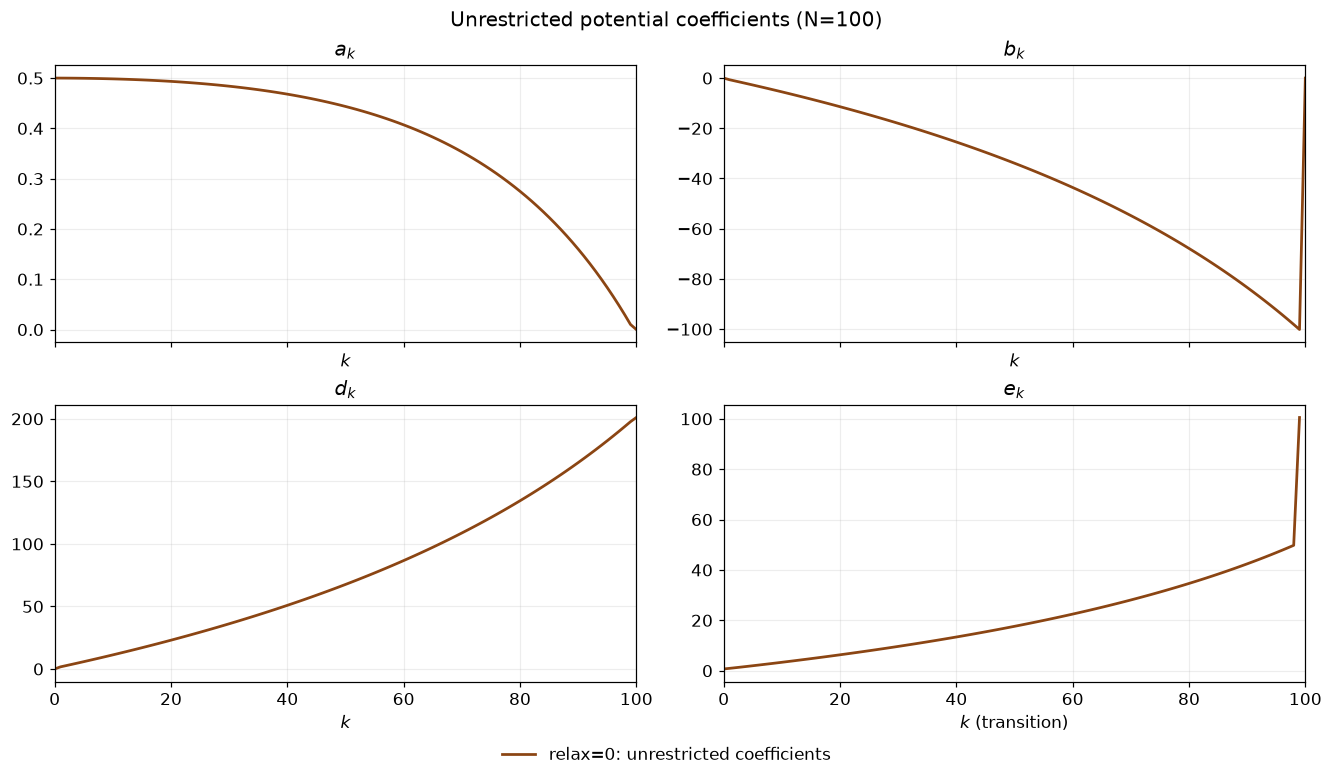

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "d", "e"), axes.flat):
    ax.plot(np.arange(len(free[key])), free[key], color="saddlebrown", linewidth=1.8,
            label="relax=0: unrestricted coefficients")
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$ (transition)" if key == "e" else r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Unrestricted potential coefficients (N={N_FIGURE})")
plt.show()

다음 반복 시점들에서 계수의 값을 표로도 확인한다.

$$k\in\{0,1,N/4,N/2,3N/4,N\}:\qquad
a_k,b_k,c_k,d_k,\quad e_k,\quad\sum_{t<k}e_t.$$

$e_k$는 $k<N$인 업데이트에만 정의되므로, 마지막 반복점에 해당하는 $k=N$에서는 개별 오차 계수 대신 그때까지의 누적합을 확인한다.


In [17]:
sample_k = sorted({0, 1, N_FIGURE // 4, N_FIGURE // 2, 3 * N_FIGURE // 4, N_FIGURE})
headers = [r"$k$", r"$a_k$", r"$b_k$", r"$c_k$", r"$d_k$", r"$e_k$（전이 $k\to k+1$）", r"$\sum_{t=0}^{k-1}e_t$"]
rows = [[k, *(f"{free[key][k]:.6g}" for key in ("a", "b", "c", "d")),
         f"{free['e'][k]:.6g}" if k < N_FIGURE else "—", f"{free['ec'][k]:.6g}"] for k in sample_k]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| $k$ | $a_k$ | $b_k$ | $c_k$ | $d_k$ | $e_k$（전이 $k\to k+1$） | $\sum_{t=0}^{k-1}e_t$ |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.5 | 0 | 0 | 0 | 0.678601 | 0 |
| 1 | 0.499951 | -0.668591 | -0.330843 | 1.68146 | 0.918259 | 0.678601 |
| 25 | 0.489277 | -14.6279 | -0.271085 | 29.372 | 7.91426 | 99.4205 |
| 50 | 0.443516 | -33.9196 | -0.146802 | 67.5495 | 17.6043 | 407.333 |
| 75 | 0.317765 | -61.0476 | 0.110681 | 121.027 | 31.2076 | 1000.24 |
| 100 | 0 | 0 | 0 | 201 | — | 2057.52 |

자유롭게 탐색한 결과 $d_{100}\approx201$을 얻었지만, 중간의 $b_k,c_k$에서 단순한 상수나 일차식의 패턴을 찾기는 어렵다. 특히 $b_k$가 음수인 구간도 보인다. 이는 $Q_k\succeq0$를 요구하지 않았기 때문에 가능한 결과다. 최종 상한은 초기·최종 경계조건과 연속된 한 단계 부등식에서 얻는다.

먼저 최종 계수 $d_N$이 반복 횟수에 따라 어떤 규칙으로 커지는지 살펴본다. 이어 oracle 결과 수를 바꾸어 본 뒤, 복잡한 중간 계수를 더 단순하게 제한하는 실험으로 넘어간다.


#### 같은 SDP를 다른 설정에서 다시 풀기

다음 셀은 3단계에서 수식과 함께 구성한 SDP를 반복해서 사용하기 위한 코드다. 실험마다 $(N,n,\mathrm{relax})$를 바꾸되, 최적화의 순서는 유지한다. 먼저 $d_N$을 최대화하고, 같은 모델에 $d_N\ge d_N^{\mathrm{opt}}-10^{-5}$를 추가한 뒤 오차 계수의 누적합을 최소화한다.


In [18]:
def build_sgd_models(specs):
    models = {spec: {"N": spec[0], "n": spec[1], "relax": spec[2]} for spec in specs}

    for model in models.values():
        n_exp = model["n"]
        dimG_exp, dimF_exp, nbPts_exp = 1 + 2 * n_exp, n_exp + 1, n_exp + 2
        basis, fbasis = np.eye(dimG_exp), np.eye(dimF_exp)
        oracle = basis[1:n_exp + 1]
        g0 = np.sum(oracle, axis=0) / n_exp
        g1 = basis[n_exp + 1:]
        xnext = basis[0] - oracle / L
        X_exp = {1: np.zeros(dimG_exp), 2: basis[0]}
        G_exp = {1: np.zeros(dimG_exp), 2: g0}
        F_exp = {1: np.zeros(dimF_exp), 2: fbasis[0]}
        for i in range(n_exp):
            X_exp[i + 3], G_exp[i + 3], F_exp[i + 3] = xnext[i], g1[i], fbasis[i + 1]
        matrices, differences = {}, {}
        for i in range(1, nbPts_exp + 1):
            for j in range(1, nbPts_exp + 1):
                if i != j:
                    TT = np.vstack((X_exp[i], X_exp[j], G_exp[i], G_exp[j]))
                    matrices[i, j] = TT.T @ M @ TT
                    differences[i, j] = F_exp[i] - F_exp[j]
        Avar_exp = np.zeros((dimG_exp, dimG_exp))
        for i in range(1, n_exp + 1):
            Avar_exp = Avar_exp + np.outer(oracle[i - 1] - g0, oracle[i - 1] - g0) / n_exp
        model.update({
            "dimG": dimG_exp, "dimF": dimF_exp, "nbPts": nbPts_exp,
            "E0": np.column_stack((basis[0], g0)),
            "E1": [np.column_stack((xnext[i], g1[i])) for i in range(n_exp)],
            "f0": fbasis[0], "f1": fbasis[1:].mean(axis=0),
            "Avar": Avar_exp,
            "interp_M": matrices, "interp_F": differences,
        })

    for model in models.values():
        N_exp, relax_exp = model["N"], model["relax"]
        tau_exp = cp.Variable(name="tau")
        final_a = L / 2 if relax_exp == 3 else 0.0
        Q_exp = {1: Q0.copy(), N_exp + 1: np.array([[final_a, 0.0], [0.0, 0.0]])}
        d_exp = {1: 0.0, N_exp + 1: tau_exp}
        lam_exp, e_exp = {}, {}
        for k in range(1, N_exp + 1):
            if k < N_exp:
                d_exp[k + 1] = cp.Variable(name=f"d_{k + 1}")
                if relax_exp == 0:
                    Q_exp[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
                elif relax_exp == 1:
                    Q_exp[k + 1] = cp.bmat([[cp.Variable(name=f"a_{k + 1}"), 0],
                                           [0, cp.Variable(name=f"b_{k + 1}")]])
                elif relax_exp == 2:
                    Q_exp[k + 1] = cp.bmat([[cp.Variable(name=f"a_{k + 1}"), 0], [0, 0]])
                else:
                    Q_exp[k + 1] = Q0.copy()
            lam_exp[k] = cp.Variable((model["nbPts"], model["nbPts"]), name=f"lambda_{k}")
            e_exp[k] = cp.Variable(name=f"e_{k}")
        model.update({"tau": tau_exp, "Q": Q_exp, "d": d_exp, "lam": lam_exp, "e": e_exp})

    for model in models.values():
        Q_exp, d_exp, e_exp = model["Q"], model["d"], model["e"]
        R_exp, q_exp = {}, {}
        for k in range(1, model["N"] + 1):
            R_exp[k] = -model["E0"] @ Q_exp[k] @ model["E0"].T - e_exp[k] * model["Avar"]
            q_exp[k] = -d_exp[k] * model["f0"]
            for E1 in model["E1"]:
                R_exp[k] = R_exp[k] + E1 @ Q_exp[k + 1] @ E1.T / model["n"]
            q_exp[k] = q_exp[k] + d_exp[k + 1] * model["f1"]
        model.update({"cons_SDP": R_exp, "cons_LIN": q_exp})

    for model in models.values():
        cons_exp = [model["tau"] >= 0]
        for k in range(1, model["N"] + 1):
            for (i, j), matrix in model["interp_M"].items():
                weight = model["lam"][k][i - 1, j - 1]
                model["cons_SDP"][k] = model["cons_SDP"][k] + weight * matrix
                model["cons_LIN"][k] = model["cons_LIN"][k] + weight * model["interp_F"][i, j]
            cons_exp += [model["cons_SDP"][k] << 0, model["cons_LIN"][k] == 0,
                         model["lam"][k] >= 0, model["e"][k] >= 0]
        model["cons"] = cons_exp

    for model in models.values():
        model["solve_cons"] = model["cons"]
        if model["relax"] == 3 and m == 0:
            solve_cons = [model["tau"] >= 0]
            for k in range(1, model["N"] + 1):
                R = model["cons_SDP"][k]
                solve_cons = solve_cons + [
                    R[0, 1:] == 0,
                    R[1:, 1:] << 0,
                    model["cons_LIN"][k] == 0,
                    model["lam"][k] >= 0,
                    model["e"][k] >= 0,
                ]
            model["solve_cons"] = solve_cons
    return models


def solve_sgd_models(models):
    for spec, model in models.items():
        model["t_start"] = perf_counter()
        problem_exp = cp.Problem(cp.Minimize(-model["tau"]), model["solve_cons"])
        solve(problem_exp, solver=solver, verbose=verbose,
              mosek_params={"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance})
        if problem_exp.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            raise RuntimeError(f"Stage 1 failed: {spec}, {problem_exp.status}")
        Q_values = np.stack([np.asarray(model["Q"][i].value if isinstance(model["Q"][i], cp.Expression)
                                       else model["Q"][i], dtype=float) for i in range(1, model["N"] + 2)])
        d_values = np.array([float(model["d"][i].value if isinstance(model["d"][i], cp.Expression)
                                   else model["d"][i]) for i in range(1, model["N"] + 2)])
        e_values = np.array([float(model["e"][k].value) for k in range(1, model["N"] + 1)])
        model["stage1"] = {
            "N": model["N"], "L": L, "n": model["n"], "relax": model["relax"],
            "a": Q_values[:, 0, 0].copy(), "b": Q_values[:, 1, 1].copy(),
            "c": Q_values[:, 1, 0].copy(), "d": d_values, "e": e_values,
            "ec": np.r_[0.0, np.cumsum(e_values)],
            "multipliers": np.stack([model["lam"][k].value.copy() for k in range(1, model["N"] + 1)]),
            "d_N": float(model["tau"].value), "sum_e": float(e_values.sum()),
            "objective": float(problem_exp.value), "status": problem_exp.status,
            "seconds": perf_counter() - model["t_start"],
        }
        print(f"Stage 1 {spec}: d_N={model['stage1']['d_N']:.8f}, status={problem_exp.status}")

    for spec, model in models.items():
        tau_floor = model["stage1"]["d_N"] - tol_reopt
        floor_constraint = model["tau"] >= tau_floor
        model["cons"] = model["cons"] + [floor_constraint]
        solve_cons = model["solve_cons"] + [floor_constraint]
        problem_exp = cp.Problem(cp.Minimize(sum(model["e"].values())), solve_cons)
        solve(problem_exp, solver=solver, verbose=verbose)
        if problem_exp.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            raise RuntimeError(f"Stage 2 failed: {spec}, {problem_exp.status}")
        Q_values = np.stack([np.asarray(model["Q"][i].value if isinstance(model["Q"][i], cp.Expression)
                                       else model["Q"][i], dtype=float) for i in range(1, model["N"] + 2)])
        d_values = np.array([float(model["d"][i].value if isinstance(model["d"][i], cp.Expression)
                                   else model["d"][i]) for i in range(1, model["N"] + 2)])
        e_values = np.array([float(model["e"][k].value) for k in range(1, model["N"] + 1)])
        result = {
            "N": model["N"], "L": L, "n": model["n"], "relax": model["relax"],
            "a": Q_values[:, 0, 0].copy(), "b": Q_values[:, 1, 1].copy(),
            "c": Q_values[:, 1, 0].copy(), "d": d_values, "e": e_values,
            "ec": np.r_[0.0, np.cumsum(e_values)],
            "multipliers": np.stack([model["lam"][k].value.copy() for k in range(1, model["N"] + 1)]),
            "d_N": float(model["tau"].value), "sum_e": float(e_values.sum()),
            "objective": float(problem_exp.value), "status": problem_exp.status,
            "seconds": perf_counter() - model["t_start"], "stage1": model["stage1"],
            "reopt_violation": max(0.0, model["stage1"]["d_N"] - tol_reopt - float(model["tau"].value)),
        }
        model["result"] = result
        print(f"Stage 2 {spec}: d_N={result['d_N']:.8f}, sum(e)={result['sum_e']:.6f}, status={result['status']}")

    for model in models.values():
        for result in (model["stage1"], model["result"]):
            R_values, eq_values, matrix_scales, eq_scales = [], [], [], []
            for t in range(model["N"]):
                Qk = np.array([[result["a"][t], result["c"][t]], [result["c"][t], result["b"][t]]])
                Qnext = np.array([[result["a"][t + 1], result["c"][t + 1]], [result["c"][t + 1], result["b"][t + 1]]])
                V0 = model["E0"] @ Qk @ model["E0"].T
                V1 = sum(E1 @ Qnext @ E1.T / model["n"] for E1 in model["E1"])
                R = V1 - V0 - result["e"][t] * model["Avar"]
                equality = result["d"][t + 1] * model["f1"] - result["d"][t] * model["f0"]
                scale = 1 + np.linalg.norm(V0, 2) + np.linalg.norm(V1, 2)
                scale += abs(result["e"][t]) * np.linalg.norm(model["Avar"], 2)
                for (i, j), matrix in model["interp_M"].items():
                    weight = result["multipliers"][t, i - 1, j - 1]
                    R += weight * matrix
                    equality += weight * model["interp_F"][i, j]
                    scale += abs(weight) * np.linalg.norm(matrix, 2)
                R_values.append(R)
                eq_values.append(equality)
                matrix_scales.append(scale)
                eq_scales.append(1 + abs(result["d"][t]) + abs(result["d"][t + 1])
                                 + np.abs(result["multipliers"][t]).sum())
            result["R"], result["equality"] = np.asarray(R_values), np.asarray(eq_values)
            result["matrix_scales"], result["equality_scales"] = np.asarray(matrix_scales), np.asarray(eq_scales)

    for model in models.values():
        for result in (model["stage1"], model["result"]):
            lmi_errors = np.maximum(0.0, np.linalg.eigvalsh(result["R"]).max(axis=1))
            eq_errors = np.abs(result["equality"]).max(axis=1)
            lambda_error = max(0.0, -float(result["multipliers"].min()))
            e_error = max(0.0, -float(result["e"].min()))
            result["residuals"] = {
                "lmi_violation": float(lmi_errors.max()),
                "equality_violation": float(eq_errors.max()),
                "multiplier_violation": lambda_error,
                "variance_multiplier_violation": e_error,
                "scaled_violation": float(max(
                    np.max(lmi_errors / result["matrix_scales"]),
                    np.max(eq_errors / result["equality_scales"]),
                    lambda_error / (1 + np.abs(result["multipliers"]).max()),
                    e_error / (1 + np.abs(result["e"]).max()),
                )),
            }
    return {spec: model["result"] for spec, model in models.items()}

### 반복 횟수를 바꾸어 최종 계수의 패턴 살펴보기

중간 potential의 계수에 추가 제약을 두지 않고(`relax=0`), oracle 결과 수는 $n=2$로 고정한다.

$$N\in\{1,2,3,4,5,10,20,50,100\},\qquad \delta_k=1/L.$$

논문 p.8에서는 $N=1,2,3,4,5,100$에서 $d_N\approx3,5,7,9,11,201$을 보고한다. 직접 계산한 결과에도 $2N+1$이라는 패턴이 나타나는지, $N=10,20,50$을 추가해 살펴본다. $2N+1$은 결과를 비교하기 위한 값이며, 제약이나 목적함수에는 넣지 않는다.

업데이트에 0부터 번호를 매기므로, 논문 표의 마지막 개별 오차 계수를 이 노트북에서는 $e_{N-1}$로 표시한다. 아래 표에서는 이를 오차 계수의 누적합 $\sum e_k$와 구분해 함께 표시한다.


In [19]:
horizons = [1, 2, 3, 4, 5, 10, 20, 50, 100]
results_by_N = {N_FIGURE: free}
horizon_specs = [(horizon, 2, 0) for horizon in horizons if horizon != N_FIGURE]
horizon_models = build_sgd_models(horizon_specs)
horizon_results = solve_sgd_models(horizon_models)
results_by_N.update({horizon: horizon_results[horizon, 2, 0]
                     for horizon in horizons if horizon != N_FIGURE})

Stage 1 (1, 2, 0): d_N=3.00000000, status=optimal
Stage 1 (2, 2, 0): d_N=4.99999996, status=optimal
Stage 1 (3, 2, 0): d_N=7.00000001, status=optimal
Stage 1 (4, 2, 0): d_N=9.00000005, status=optimal
Stage 1 (5, 2, 0): d_N=11.00000001, status=optimal


Stage 1 (10, 2, 0): d_N=21.00000004, status=optimal


Stage 1 (20, 2, 0): d_N=41.00000047, status=optimal


Stage 1 (50, 2, 0): d_N=101.00000247, status=optimal
Stage 2 (1, 2, 0): d_N=2.99998998, sum(e)=1.499995, status=optimal
Stage 2 (2, 2, 0): d_N=4.99998996, sum(e)=3.408561, status=optimal
Stage 2 (3, 2, 0): d_N=6.99999000, sum(e)=5.692012, status=optimal
Stage 2 (4, 2, 0): d_N=8.99998969, sum(e)=8.354197, status=optimal
Stage 2 (5, 2, 0): d_N=10.99998947, sum(e)=11.397954, status=optimal


Stage 2 (10, 2, 0): d_N=20.99998769, sum(e)=32.374726, status=optimal


Stage 2 (20, 2, 0): d_N=40.99998614, sum(e)=103.224948, status=optimal


Stage 2 (50, 2, 0): d_N=100.99998081, sum(e)=547.165408, status=optimal


| $N$ | 첫 번째 $d_N$ | 두 번째 $d_N$ | 논문 $d_N$ | $d_N/(2N+1)$ | $e_{N-1}$ | 논문 $e_{N-1}$ | $\sum e_k$ | $(\sum e_k)/d_N$ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 3.00000000 | 2.99998998 | 3 | 0.99999666 | 1.499995 | 1.5 | 1.499995 | 0.5 |
| 2 | 4.99999996 | 4.99998996 | 5 | 0.99999799 | 2.499995 | 2.5 | 3.408561 | 0.681714 |
| 3 | 7.00000001 | 6.99999000 | 7 | 0.99999857 | 3.499995 | 3.5 | 5.692012 | 0.813146 |
| 4 | 9.00000005 | 8.99998969 | 9 | 0.99999885 | 4.500003 | 4.5 | 8.354197 | 0.928245 |
| 5 | 11.00000001 | 10.99998947 | 11 | 0.99999904 | 5.500011 | 5.5 | 11.397954 | 1.03618 |
| 10 | 21.00000004 | 20.99998769 | — | 0.99999941 | 10.500084 | — | 32.374726 | 1.54165 |
| 20 | 41.00000047 | 40.99998614 | — | 0.99999966 | 20.500262 | — | 103.224948 | 2.51768 |
| 50 | 101.00000247 | 100.99998081 | — | 0.99999981 | 50.501037 | — | 547.165408 | 5.41748 |
| 100 | 201.00000890 | 200.99996241 | 201 | 0.99999981 | 100.503632 | 100.5 | 2057.522911 | 10.2364 |

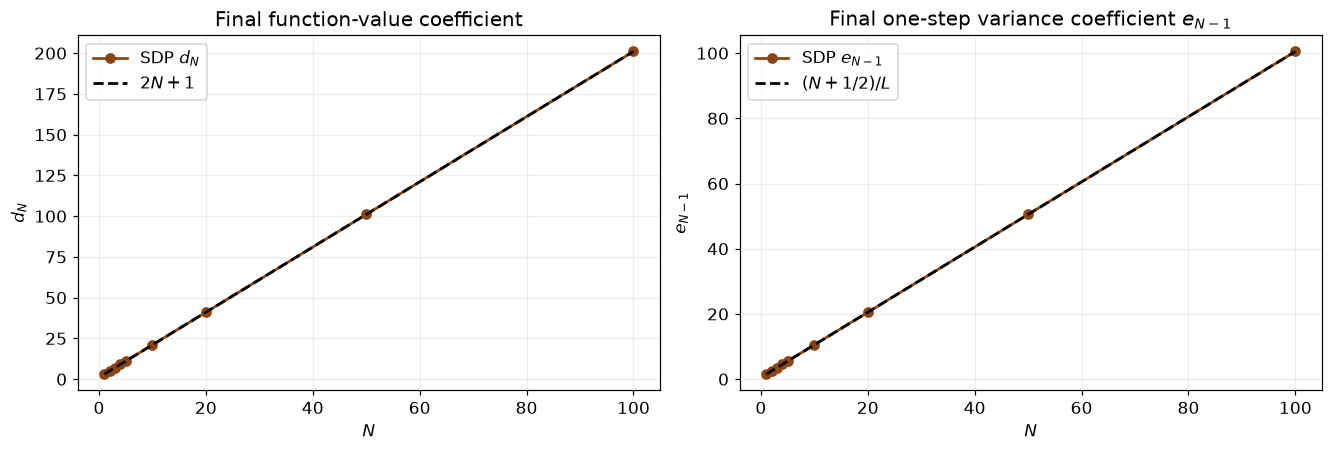

In [20]:
paper_values = {1: 3, 2: 5, 3: 7, 4: 9, 5: 11, 100: 201}
headers = [r"$N$", r"첫 번째 $d_N$", r"두 번째 $d_N$", r"논문 $d_N$", r"$d_N/(2N+1)$", r"$e_{N-1}$", r"논문 $e_{N-1}$", r"$\sum e_k$", r"$(\sum e_k)/d_N$"]
rows = []
for horizon in horizons:
    result = results_by_N[horizon]
    rows.append([horizon, f"{result['stage1']['d_N']:.8f}", f"{result['d_N']:.8f}",
                 paper_values.get(horizon, "—"), f"{result['d_N']/(2*horizon + 1):.8f}",
                 f"{result['e'][-1]:.6f}", paper_values[horizon]/(2 * L) if horizon in paper_values else "—",
                 f"{result['sum_e']:.6f}", f"{result['sum_e']/result['d_N']:.6g}"])
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

Ns = np.array(horizons)
dNs = np.array([results_by_N[horizon]["d_N"] for horizon in horizons])
last_es = np.array([results_by_N[horizon]["e"][-1] for horizon in horizons])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(Ns, dNs, "o-", color="saddlebrown", linewidth=1.8, label=r"SDP $d_N$")
axes[0].plot(Ns, 2 * Ns + 1, "--", color="black", linewidth=1.8, label=r"$2N + 1$")
axes[0].set(xlabel=r"$N$", ylabel=r"$d_N$", title="Final function-value coefficient")
axes[1].plot(Ns, last_es, "o-", color="saddlebrown", linewidth=1.8, label=r"SDP $e_{N-1}$")
axes[1].plot(Ns, (Ns + 0.5)/L, "--", color="black", linewidth=1.8, label=r"$(N + 1/2)/L$")
axes[1].set(xlabel=r"$N$", ylabel=r"$e_{N-1}$", title=r"Final one-step variance coefficient $e_{N-1}$")
for ax in axes:
    ax.legend()
plt.show()

실험한 반복 횟수에서 $d_N/(2N+1)$은 거의 $1$이고, 마지막 개별 오차 계수는 약 $(N+1/2)/L$이다. 이 결과는 초기 거리항의 계수 $L/(2d_N)$가 $O(N^{-1})$로 작아지는 패턴을 보여 준다.

그러나 마지막 오차 계수 하나로 전체 분산 항을 판단할 수는 없다. $N=100$에서는 누적합이 약 $2057.52$이고, 최종 상한에 들어가는 $(\sum e_k)/d_N$은 약 $10.2364$이다. 이 차이를 염두에 두고, 다음에는 oracle의 가능한 결과 수를 늘려도 같은 패턴이 유지되는지 확인한다.


#### 후속 비교: oracle 결과 수를 2개에서 10개로 늘리기

위 결과가 두 가지 값만 반환하는 oracle에서만 나타나는 현상인지 살펴본다. $N=1,2,5$와 `relax=0`은 유지하고, 가능한 oracle 결과 수를 $n=10$으로 바꾼다.

$$G\in\mathbb S_+^{1+2n},\qquad F\in\mathbb R^{1\times(n+1)},\qquad
\mathbf g_0=\frac1n\sum_{i=1}^n\mathbf G_i,\qquad
\mathbf x_i=\mathbf x_0-\mathbf G_i/L.$$

따라서 $n=10$에서는 LMI의 크기가 $21\times21$이고, 한 단계에서 함수값 항의 계수를 소거하는 등식은 11개, interpolation 부등식은 132개다. 목적함수와 potential의 경계조건은 앞 실험과 같다.


In [21]:
support_specs = [(horizon, 10, 0) for horizon in (1, 2, 5)]
support_models = build_sgd_models(support_specs)
support_solutions = solve_sgd_models(support_models)
support_results = {horizon: support_solutions[horizon, 10, 0] for horizon in (1, 2, 5)}

Stage 1 (1, 10, 0): d_N=3.00000000, status=optimal
Stage 1 (2, 10, 0): d_N=5.00000002, status=optimal


Stage 1 (5, 10, 0): d_N=11.00000006, status=optimal
Stage 2 (1, 10, 0): d_N=2.99998995, sum(e)=1.499995, status=optimal
Stage 2 (2, 10, 0): d_N=4.99998998, sum(e)=3.408559, status=optimal


Stage 2 (5, 10, 0): d_N=10.99999006, sum(e)=11.398242, status=optimal


In [22]:
headers = [r"$N$", r"$n=2$: $d_N$", r"$n=10$: $d_N$", r"$n=2$: $e_{N-1}$", r"$n=10$: $e_{N-1}$"]
rows = []
for horizon, result in support_results.items():
    baseline = results_by_N[horizon]
    rows.append([horizon, f"{baseline['d_N']:.8f}", f"{result['d_N']:.8f}",
                 f"{baseline['e'][-1]:.6f}", f"{result['e'][-1]:.6f}"])
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| $N$ | $n=2$: $d_N$ | $n=10$: $d_N$ | $n=2$: $e_{N-1}$ | $n=10$: $e_{N-1}$ |
| --- | --- | --- | --- | --- |
| 1 | 2.99998998 | 2.99998995 | 1.499995 | 1.499995 |
| 2 | 4.99998996 | 4.99998998 | 2.499995 | 2.499997 |
| 5 | 10.99998947 | 10.99999006 | 5.500011 | 5.499995 |

세 반복 횟수 모두에서 $n=2$와 $n=10$의 $d_N$ 및 마지막 개별 오차 계수는 수치적으로 가깝다. 실험한 범위에서는 oracle 결과 수를 늘려도 $2N+1$ 패턴이 유지되는 셈이다.

5단계의 Theorem 5에서는 특정 계수 수열이 한 단계 부등식을 만족함을 증명하여, 결과 수에 의존하지 않는 결론을 얻는다. 그 수열을 찾기 위해, 이제 자유롭게 탐색했던 potential의 계수를 차례로 제한해 본다.


### 계수를 제한하며 단순한 potential 찾기

계수를 자유롭게 탐색하면 큰 $d_N$을 얻을 수 있지만, 계수 수열은 복잡하다. 이번에는 $N=100,n=2,L=1$로 돌아와, 교차항을 없애고 gradient norm 제곱 항을 없앤 뒤 거리항의 계수를 고정한다.

$$\phi_k^f\quad\longrightarrow\quad
a_k\|x_k-x_\star\|^2+d_k(f(x_k)-f_\star)
\quad\longrightarrow\quad
\frac L2\|x_k-x_\star\|^2+d_k(f(x_k)-f_\star).$$

이렇게 단순화하면서 $d_N$과 최종 상한에서 분산 항의 계수 $(\sum e_k)/d_N$이 각각 얼마나 달라지는지 비교한다.


#### 네 설정의 계수 제한과 경계조건

같은 $N=100,n=2,L=1$에서 아래 네 설정을 비교한다. 표의 중간 상태는 $k=1,\ldots,N-1$이다.

| `relax` | 중간 potential에 추가하는 조건 | 색 / 선 | $a_N$ | 최종 potential |
| --- | --- | --- | --- | --- |
| 0 | 없음 | 갈색 실선 | $0$ | $d_N(f(x_N)-f_\star)$ |
| 1 | $c_k=0$ | 빨간 점선 | $0$ | $d_N(f(x_N)-f_\star)$ |
| 2 | $b_k=c_k=0$ | 파란 점선 | $0$ | $d_N(f(x_N)-f_\star)$ |
| 3 | $b_k=c_k=0,\ a_k=L/2$ | 보라 점선 | $L/2$ | $\frac L2\|x_N-x_\star\|^2+d_N(f(x_N)-f_\star)$ |

모든 설정에서 $a_0=L/2$, $b_0=c_0=d_0=b_N=c_N=0$이며, $d_N$은 최적화 변수다. 이 경계조건은 참조 Python 코드를 따른다. 같은 `relax` 번호라도 GD 노트북에서의 제약과는 다르다.

**`relax=3`은 $\phi_N^f=d_N(f(x_N)-f_\star)+\frac L2\|x_N-x_\star\|^2$를 사용한다.** 따라서 중간 계수의 제한뿐 아니라 최종 경계조건도 함께 바뀐다. 남아 있는 거리항은 비음수이므로 버릴 수 있고, 그 결과 모든 설정에서 같은 형태의 함수값 상한을 얻는다. 비교할 때는 $d_N$, $\sum e_k$, $(\sum e_k)/d_N$을 함께 본다.


`m=0`, $a_k=L/2$, $b_k=c_k=0$인 `relax=3`에서는 LMI 좌변의 첫 대각 성분이 항상 0이다. 음의 준정부호 행렬에서 대각 성분이 0이면 해당 행과 열의 나머지 성분도 0이어야 한다. 따라서 SDP 구성 함수는 첫 행의 비대각 성분을 모두 0으로 두고, 첫 행과 열을 제외한 주부분행렬에 음의 준정부호 조건을 등록한다.

이 두 조건은 이 설정의 전체 LMI와 동치다. 원래의 전체 행렬도 같은 계수로 계산하며, 함수값 항의 소거 조건은 그대로 둔다. 두 목적함수와 MOSEK 설정은 앞 실험과 같다.


In [23]:
figure_results = {0: free}
figure_specs = [(N_FIGURE, 2, relaxation) for relaxation in (1, 2, 3)]
figure_models = build_sgd_models(figure_specs)
figure_solutions = solve_sgd_models(figure_models)
figure_results.update({relaxation: figure_solutions[N_FIGURE, 2, relaxation]
                       for relaxation in (1, 2, 3)})

Stage 1 (100, 2, 1): d_N=201.00001634, status=optimal


Stage 1 (100, 2, 2): d_N=201.00001027, status=optimal


Stage 1 (100, 2, 3): d_N=99.99999981, status=optimal


Stage 2 (100, 2, 1): d_N=200.99999524, sum(e)=2058.992045, status=optimal


Stage 2 (100, 2, 2): d_N=200.99993663, sum(e)=3961.491883, status=optimal


Stage 2 (100, 2, 3): d_N=99.99998909, sum(e)=2574.999497, status=optimal


#### Figure 2: 네 설정의 계수 수열 비교하기

각 패널은 $a_k,b_k,d_k,e_k$를 같은 축에서 비교한다. 색과 선의 구분은 앞의 GD 노트북과 같다. 교차항 계수 $c_k$와 오차 계수의 누적합 $\sum_{t<k}e_t$는 이어지는 그림에서 별도로 살펴본다.


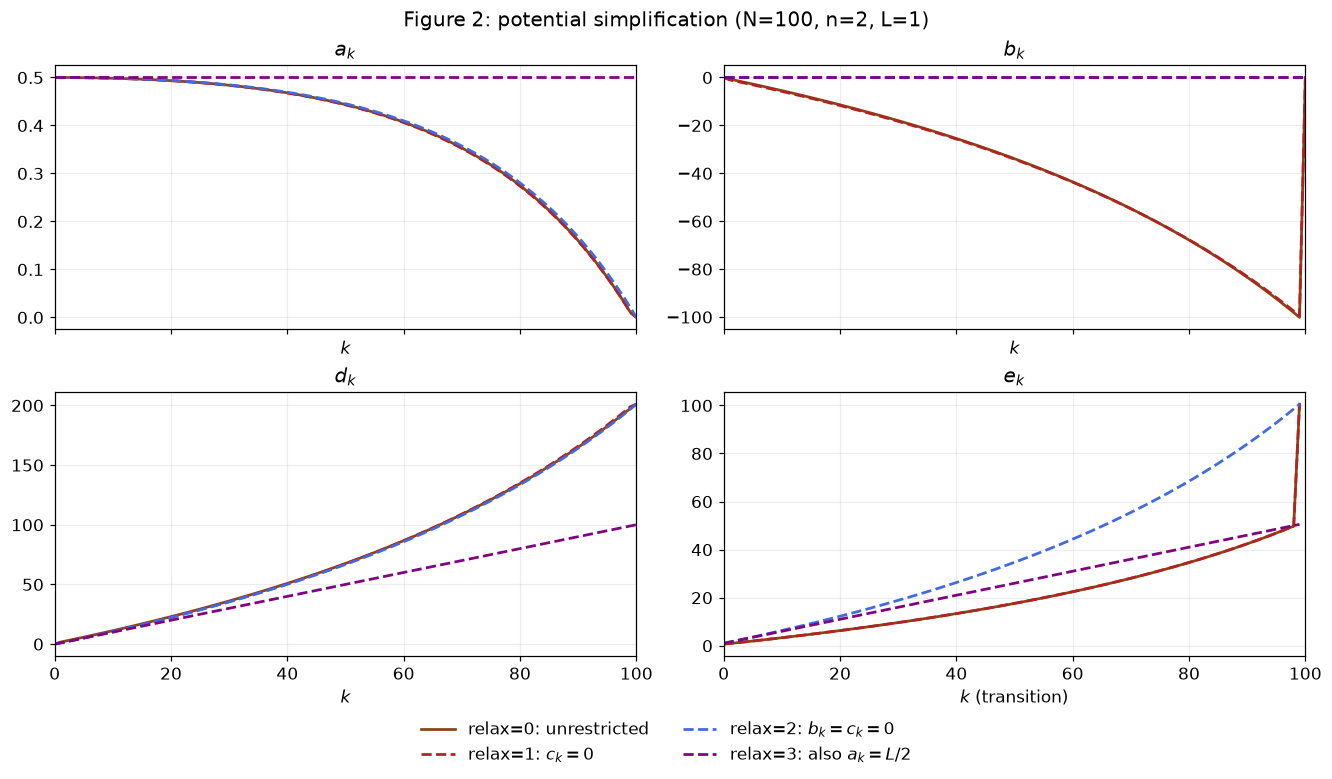

In [24]:
styles = {
    0: ("relax=0: unrestricted", "saddlebrown", "-"),
    1: (r"relax=1: $c_k=0$", "firebrick", "--"),
    2: (r"relax=2: $b_k=c_k=0$", "royalblue", "--"),
    3: (r"relax=3: also $a_k=L/2$", "purple", "--"),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "d", "e"), axes.flat):
    for relaxation in range(4):
        result = figure_results[relaxation]
        label, color, linestyle = styles[relaxation]
        ax.plot(np.arange(len(result[key])), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$ (transition)" if key == "e" else r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Figure 2: potential simplification (N={N_FIGURE}, n={n}, L={L:g})")
plt.show()

계수 곡선에 이어, $d_N$과 $\sum_{k<N}e_k$를 표로 비교한다. 특히 `relax=3`은 최종 거리항을 유지한다는 점을 고려하면서, 실제 상한에 들어가는 다음 두 계수를 비교한다.

$$\frac{L}{2d_N},\qquad\frac{\sum_{k=0}^{N-1}e_k}{d_N}.$$


In [25]:
headers = ["설정", r"$d_N$", r"$e_{N-1}$", r"$\sum e_k$", r"$L/(2d_N)$", r"$(\sum e_k)/d_N$", "상태"]
rows = [[relaxation, f"{result['d_N']:.8f}", f"{result['e'][-1]:.6f}",
         f"{result['sum_e']:.6f}", f"{L/(2*result['d_N']):.6g}",
         f"{result['sum_e']/result['d_N']:.6g}", result["status"]]
        for relaxation, result in sorted(figure_results.items())]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| 설정 | $d_N$ | $e_{N-1}$ | $\sum e_k$ | $L/(2d_N)$ | $(\sum e_k)/d_N$ | 상태 |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 200.99996241 | 100.503632 | 2057.522911 | 0.00248756 | 10.2364 | optimal |
| 1 | 200.99999524 | 100.502118 | 2058.992045 | 0.00248756 | 10.2437 | optimal |
| 2 | 200.99993663 | 100.509943 | 3961.491883 | 0.00248756 | 19.7089 | optimal |
| 3 | 99.99998909 | 50.499995 | 2574.999497 | 0.005 | 25.75 | optimal |

교차항을 없앤 `relax=1`은 자유롭게 탐색한 해와 거의 같은 $d_{100}\approx201$을 얻고, 분산 항의 계수도 약 $10.24$로 가깝다. Gradient norm 제곱 항까지 없앤 `relax=2` 역시 $d_{100}\approx201$을 유지하지만, 분산 항의 계수는 약 $19.71$로 커진다. 따라서 $d_N$이 같다는 사실만으로 최종 함수값 상한까지 같다고 할 수는 없다.

거리항의 계수를 $L/2$로 고정한 `relax=3`에서는 $d_{100}\approx100$, 분산 항의 계수 약 $25.75$를 얻는다. 이때 $d_k,e_k$는 그래프에서 단순한 증가 패턴을 보인다. 계수의 자유도를 줄이면서 수치 상한은 달라졌지만, 모든 반복에서 potential 부등식을 만족하는 명시적 수열을 추측할 근거가 생겼다.


#### 교차항의 계수와 오차 계수의 누적합 살펴보기

왼쪽은 교차항 계수 $c_k=(Q_k)_{12}$, 오른쪽은 $k$번째 반복점에 도달할 때까지 오차 계수를 더한 값

$$\sum_{t=0}^{k-1}e_t$$

을 보여 준다. 오른쪽 곡선의 끝점이 앞 표의 $\sum_{k=0}^{N-1}e_k$에 해당한다.


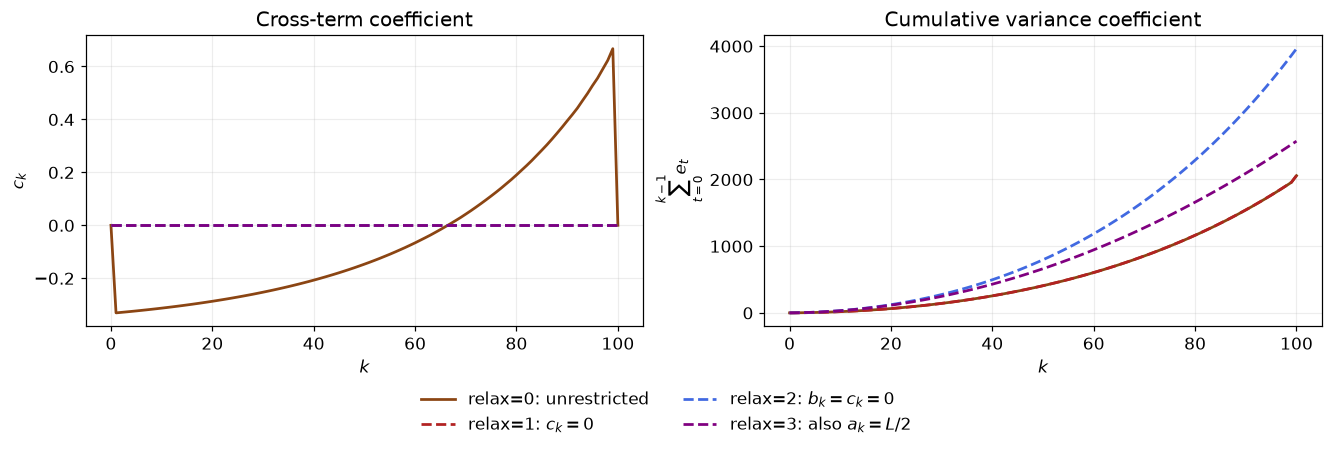

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for relaxation in range(4):
    result = figure_results[relaxation]
    label, color, linestyle = styles[relaxation]
    axes[0].plot(np.arange(N_FIGURE + 1), result["c"], label=label, color=color,
                 linestyle=linestyle, linewidth=1.8)
    axes[1].plot(np.arange(N_FIGURE + 1), result["ec"], label=label, color=color,
                 linestyle=linestyle, linewidth=1.8)
axes[0].set(xlabel=r"$k$", ylabel=r"$c_k$", title="Cross-term coefficient")
axes[1].set(xlabel=r"$k$", ylabel=r"$\sum_{t=0}^{k-1}e_t$", title="Cumulative variance coefficient")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()

### 해석적 증명에 사용할 단순한 potential

계수를 차례로 제한한 끝에 남은 형태는 다음과 같다.

$$\boxed{\phi_k^f=\frac L2\|x_k-x_\star\|^2+d_k(f(x_k)-f_\star)}$$

거리항의 계수는 고정되었고, 이제 정해야 할 것은 함수값 계수 $d_k$와 각 업데이트의 오차 계수 $e_k$다. 5단계에서는 $d_k,e_k$의 점화식과 multiplier를 명시해 이 potential에 대한 조건부 기대값 부등식을 증명한다.


## 5단계 · 해석적 potential inequality와 수렴률

4단계에서 선택한 단순한 potential에 대해, 이제 매 업데이트에 적용할 계수와 부등식을 명시한다. Theorem 5의 명시적 $d_k,e_k$를 SDP 수치해와 비교한 뒤, 한 단계 potential inequality와 telescoping 상한을 증명한다.

### Theorem 5의 점화식과 명시적 계수

Theorem 5는 $d_k,\delta_k\ge0$이고

$$\boxed{d_{k+1}=d_k+\delta_kL,\qquad
e_k=\frac{\delta_k^2L}{2}(1+d_{k+1}),\qquad
\delta_kd_{k+1}\ge e_k}$$

이면 위의 단순한 potential이 $\mathbb E_i[\phi_{k+1}^f]\le\phi_k^f+e_k\sigma^2$를 만족함을 보장한다. 특히 $0\le\delta_k\le1/L$이면 마지막 조건이 보장된다.

Figure 2의 step-size $\delta_k=1/L$와 초기값 $d_0=0$을 대입하면

$$\boxed{a_k=L/2,\qquad b_k=c_k=0,\qquad d_k=k,\qquad e_k=\frac{k+2}{2L}.}$$

따라서 $d_N=N$이고, 마지막 개별 오차 계수는 $e_{N-1}=(N+1)/(2L)$이며, 오차 계수의 누적합은

$$\sum_{k=0}^{N-1}e_k=\frac{N(N+3)}{4L}$$

이다. 이 수열을 `relax=3`의 수치해와 겹쳐 그린다. 두 결과는 같은 potential 구조와 같은 형태의 초기·최종 조건을 사용한다. 다만 정리가 보장하는 것은 **명시된 수열이 potential 부등식을 만족한다는 사실**이므로, SDP 해와의 일치 여부는 실제 결과에서 확인해야 한다. 논문이 Figure 2의 보라 곡선과 연결한 해석적 수열을, 여기서는 직접 계산한 수치해와 구분해 표시한다.


In [27]:
k = np.arange(N_FIGURE + 1)
transitions = np.arange(N_FIGURE)
analytical = {
    "a": np.full(N_FIGURE + 1, L/2),
    "b": np.zeros(N_FIGURE + 1), "c": np.zeros(N_FIGURE + 1),
    "d": k.astype(float), "e": (transitions + 2) / (2 * L),
}
analytical["ec"] = np.r_[0.0, np.cumsum(analytical["e"])]
simplified = figure_results[3]

검정 점선은 다음 해석적 계수이고, 보라 실선은 `relax=3`에서 얻은 수치 계수다.

$$a_k=L/2,\qquad b_k=c_k=0,\qquad d_k=k,\qquad e_k=(k+2)/(2L).$$

Potential 계수는 $k=0,\ldots,N$, 오차 계수는 $k=0,\ldots,N-1$에서 비교한다.


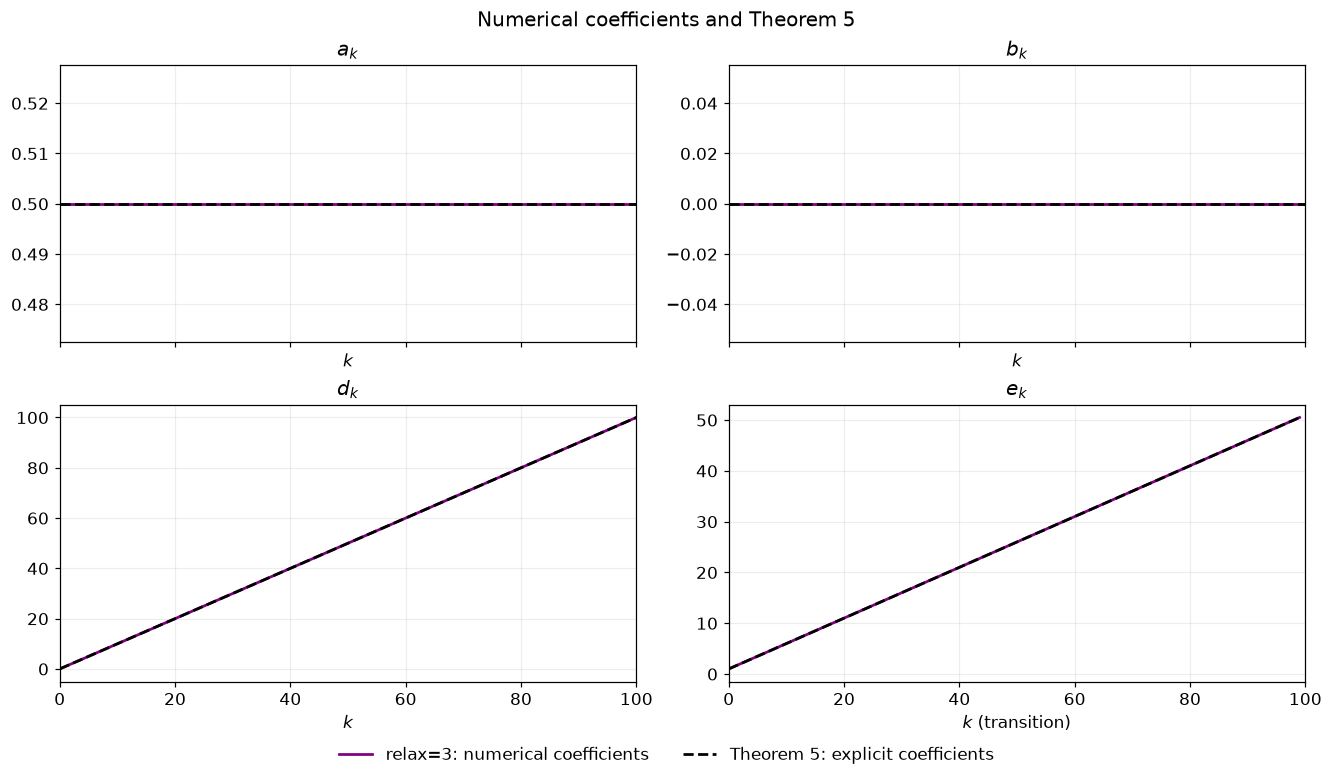

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "d", "e"), axes.flat):
    ax.plot(np.arange(len(simplified[key])), simplified[key], color="purple", linewidth=1.8,
            label="relax=3: numerical coefficients")
    ax.plot(np.arange(len(analytical[key])), analytical[key], color="black", linestyle="--",
            linewidth=1.8, label="Theorem 5: explicit coefficients")
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$ (transition)" if key == "e" else r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Numerical coefficients and Theorem 5")
plt.show()

### 기본 SDP·제약 SDP·Theorem 5의 계수 비교

세 결과는 같은 초기 거리항에서 출발한다. 아래 표에는 $\phi_N^f$와 함수값 상한의 계수 $L/(2d_N)$, $(\sum e_k)/d_N$을 모았다. `analytical`은 앞의 점화식으로 직접 만든 수열이며, 별도의 SDP를 푼 결과가 아니다.


In [29]:
headers = ["대상", "최종 potential", r"$d_N$", r"$\sum e_k$", r"$L/(2d_N)$", r"$(\sum e_k)/d_N$"]
rows = []
for label, result, final_potential in (
    ("자유 potential 수치해", free, r"$d_N(f(x_N)-f_\star)$"),
    ("relax=3 수치해", simplified, r"$(L/2)\|x_N-x_\star\|^2+d_N(f(x_N)-f_\star)$"),
    ("Theorem 5", analytical, r"$(L/2)\|x_N-x_\star\|^2+d_N(f(x_N)-f_\star)$"),
):
    d_final = float(result["d"][-1])
    sum_e = float(result["ec"][-1])
    rows.append([label, final_potential, f"{d_final:.8f}", f"{sum_e:.6f}",
                 f"{L/(2*d_final):.6g}", f"{sum_e/d_final:.6g}"])
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| 대상 | 최종 potential | $d_N$ | $\sum e_k$ | $L/(2d_N)$ | $(\sum e_k)/d_N$ |
| --- | --- | --- | --- | --- | --- |
| 자유 potential 수치해 | $d_N(f(x_N)-f_\star)$ | 200.99996241 | 2057.522911 | 0.00248756 | 10.2364 |
| relax=3 수치해 | $(L/2)\|x_N-x_\star\|^2+d_N(f(x_N)-f_\star)$ | 99.99998909 | 2574.999497 | 0.005 | 25.75 |
| Theorem 5 | $(L/2)\|x_N-x_\star\|^2+d_N(f(x_N)-f_\star)$ | 100.00000000 | 2575.000000 | 0.005 | 25.75 |

기본 설정에서는 중간 계수의 자유도가 더 크고, $\phi_N^f=d_N(f(x_N)-f_\star)$로 둔다. 이때 $d_{100}\approx201$, 분산 항의 계수 약 $10.24$를 얻는다. Theorem 5는 최종 거리항을 유지하는 단순한 potential에 대해 $d_{100}=100$, 분산 항의 계수 $25.75$인 명시적 수열이 potential 부등식을 만족함을 보장한다. 두 결과를 비교할 때는 목적과 경계조건의 차이도 고려해야 한다.

같은 단순 potential 구조를 사용하는 `relax=3`의 수치해와 Theorem 5를 비교하면, 이번 설정에서는 계수와 최종 상한이 매우 가깝다. 이 관찰을 모든 단계에 대한 증명으로 연결하려면, 점화식에 맞는 multiplier를 직접 정하고 그 가중합이 원하는 부등식을 준다는 것을 보여야 한다.


아래 표는 `relax=3`과 Theorem 5의 각 계수에 대해 마지막 값과 전체 인덱스에서의 최대 절댓값 차이를 보여 준다. 개별 오차 계수의 마지막 값은 $e_{N-1}$이고, 누적합의 마지막 값은 $\sum_{k=0}^{N-1}e_k$다.


In [30]:
coefficient_labels = {"a": r"$a_k$", "b": r"$b_k$", "c": r"$c_k$", "d": r"$d_k$", "e": r"$e_k$", "ec": r"$\sum_{t=0}^{k-1}e_t$"}
headers = ["계수", "수치해의 마지막 값", "Theorem 5의 마지막 값", r"$k$ 전체의 최대 절댓값 차이"]
rows = [[coefficient_labels[key], f"{simplified[key][-1]:.8g}", f"{analytical[key][-1]:.8g}",
         f"{np.max(np.abs(simplified[key] - analytical[key])):.6g}"]
        for key in ("a", "b", "c", "d", "e", "ec")]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))
print(f"SDP d_N - N = {simplified['d_N'] - N_FIGURE:+.8g}")
print(f"Theorem 5 sum(e) = {analytical['ec'][-1]:.8g}; N(N+3)/(4L) = {N_FIGURE*(N_FIGURE + 3)/(4 * L):.8g}")

| 계수 | 수치해의 마지막 값 | Theorem 5의 마지막 값 | $k$ 전체의 최대 절댓값 차이 |
| --- | --- | --- | --- |
| $a_k$ | 0.5 | 0.5 | 0 |
| $b_k$ | 0 | 0 | 0 |
| $c_k$ | 0 | 0 | 0 |
| $d_k$ | 99.999989 | 100 | 1.10558e-05 |
| $e_k$ | 50.499995 | 50.5 | 5.15264e-06 |
| $\sum_{t=0}^{k-1}e_t$ | 2574.9995 | 2575 | 0.000502982 |

SDP d_N - N = -1.0906695e-05
Theorem 5 sum(e) = 2575; N(N+3)/(4L) = 2575


### 해석적 수열이 LMI를 만족하는 이유

Theorem 5의 수열은 $a_k=L/2$, $b_k=c_k=0$, $d_k=k$, $e_k=(k+2)/(2L)$이다. 이를 3단계에서 구성한 LMI에 대입한다. 먼저 일반적인 step-size에서

$$d_{k+1}=d_k+L\delta_k,\qquad
 e_k=\frac{L\delta_k^2}{2}(1+d_{k+1})$$

를 사용한다. Appendix E.7의 점 번호에 따라 모든 $n$에 대해 다음 multiplier를 선택한다.

$$\boxed{\lambda_{\star,0}=L\delta_k,\qquad
\lambda_{0,i}=\frac{d_{k+1}}n\quad(i=1,\ldots,n),\qquad
\text{나머지 }\lambda_{p,q}=0.}$$

함수값 계수는 $d_{k+1}-d_k-L\delta_k=0$으로 소거된다. 위 multiplier를 대입한 LMI 좌변은 다음과 같다.

$$\boxed{\begin{aligned}
&\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k-e_kA_{\mathrm{var}}
+L\delta_kM_{\star,0}+\frac{d_{k+1}}n\sum_{i=1}^nM_{0,i}\\
&=-\left(\delta_kd_{k+1}-e_k+\frac{\delta_k}{2}\right)\mathbf g_0\mathbf g_0^\top\\
&\quad-\frac{d_{k+1}}{2Ln}\sum_{i=1}^n
(\mathbf g_i-\mathbf g_0+L\delta_k\mathbf G_i)
(\mathbf g_i-\mathbf g_0+L\delta_k\mathbf G_i)^\top\preceq0.
\end{aligned}}$$

Theorem 5의 조건 $\delta_kd_{k+1}\ge e_k$와 $d_k,\delta_k\ge0$에 의해 오른쪽은 음의 준정부호다. 특히 $\delta_k=1/L$, $d_k=k$이면

$$\begin{aligned}
&\frac1n\sum_{i=1}^nV_{k+1}^{(i)}-V_k-e_kA_{\mathrm{var}}
+M_{\star,0}+\frac{k+1}n\sum_{i=1}^nM_{0,i}\\
&=-\frac{k+1}{2L}\left[\mathbf g_0\mathbf g_0^\top+
\frac1n\sum_{i=1}^n(\mathbf g_i-\mathbf g_0+\mathbf G_i)
(\mathbf g_i-\mathbf g_0+\mathbf G_i)^\top\right].
\end{aligned}$$

아래에서는 SDP를 다시 풀지 않고 알려진 계수와 multiplier를 대입해 행렬을 구성한다. 수치 대입 결과를 확인한 뒤, 이어지는 증명에서 이 항등식이 모든 반복에서 성립함을 보인다.


In [31]:
# Point indices: 1 = star, 2 = current, 3,...,n+2 = stochastic next points.
explicit_multipliers = np.zeros((N_FIGURE, nbPts, nbPts))
for t in range(N_FIGURE):
    explicit_multipliers[t, 0, 1] = 1.0  # L * delta = 1.
    for i in range(n):
        explicit_multipliers[t, 1, i + 2] = (t + 1) / n

R_values, eq_values = [], []
for t in range(N_FIGURE):
    Qk = np.array([[L / 2, 0.0], [0.0, 0.0]])
    R = -statesKG @ Qk @ statesKG.T - analytical["e"][t] * Avar
    equality = -analytical["d"][t] * fxk
    for i in range(n):
        E1 = np.column_stack((XK1[i] - xs, gxk1[i]))
        R += E1 @ Qk @ E1.T / n
        equality += analytical["d"][t + 1] * fxk1[i] / n
    for (i, j), matrix in interp_M.items():
        weight = explicit_multipliers[t, i - 1, j - 1]
        R += weight * matrix
        equality += weight * interp_F[i, j]
    R_values.append(R)
    eq_values.append(equality)
analytic_check = {"R": np.asarray(R_values), "equality": np.asarray(eq_values)}

앞에서 직접 구성한 LMI 좌변을 다음 명시적 행렬과 비교한다. $\delta_k=1/L$, $d_k=k$일 때의 항등식이며, 모든 반복에 대해 두 행렬의 차이와 제약 위반을 계산한다.

$$-\frac{k+1}{2L}\left[\mathbf g_0\mathbf g_0^\top+\frac1n\sum_{i=1}^n(\mathbf g_i-\mathbf g_0+\mathbf G_i)(\mathbf g_i-\mathbf g_0+\mathbf G_i)^\top\right].$$


In [32]:
w = gxk1 - gxk + Gxk
base_matrix = np.outer(gxk, gxk) + w.T @ w / n
expected_R = -((np.arange(N_FIGURE) + 1) / (2 * L))[:, None, None] * base_matrix
matrix_identity_error = float(np.max(np.abs(analytic_check["R"] - expected_R)))
analytic_check.update({
    "lmi_violation": max(0.0, float(np.linalg.eigvalsh(analytic_check["R"]).max())),
    "equality_violation": float(np.abs(analytic_check["equality"]).max()),
    "multiplier_violation": max(0.0, -float(explicit_multipliers.min())),
})
headers = ["항등식·제약", "최대 오차"]
rows = [
    ["LMI 좌변의 양의 고윳값", f"{analytic_check['lmi_violation']:.3e}"],
    ["함수값 계수 등식", f"{analytic_check['equality_violation']:.3e}"],
    ["Multiplier 비음수 조건", f"{analytic_check['multiplier_violation']:.3e}"],
    ["행렬 항등식", f"{matrix_identity_error:.3e}"],
    ["$d_{k+1}-d_k=1$", f"{np.max(np.abs(np.diff(analytical['d']) - 1)):.3e}"],
    ["$e_k=(k+2)/(2L)$", f"{np.max(np.abs(analytical['e'] - (1 + analytical['d'][1:]) / (2 * L))):.3e}"],
]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| 항등식·제약 | 최대 오차 |
| --- | --- |
| LMI 좌변의 양의 고윳값 | 1.216e-14 |
| 함수값 계수 등식 | 0.000e+00 |
| Multiplier 비음수 조건 | 0.000e+00 |
| 행렬 항등식 | 0.000e+00 |
| $d_{k+1}-d_k=1$ | 0.000e+00 |
| $e_k=(k+2)/(2L)$ | 0.000e+00 |

### Appendix E.1. 조건부 기대값 부등식의 증명

1단계의 알고리즘과 가정으로 돌아가, Theorem 5의 계수가 potential inequality를 보장함을 증명한다. 한 단계 업데이트를 분석하기 위해 $x_k$까지의 정보를 고정한다. 이 절의 $\mathbb E_i$는 모두 이번 oracle 선택에 대한 조건부 기대값이다. 업데이트

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
\mathbb E_i[G(x_k;i)]=f'(x_k)$$

를 그대로 사용한다. 증명에 필요한 부등식은 세 개다.

**Convexity**에서

$$f(x_k)-f_\star-\langle f'(x_k),x_k-x_\star\rangle\le0$$

를 얻는다. **Smoothness**를 각 다음 점에 적용하고 평균을 취하면

$$\begin{aligned}
&\mathbb E_i[f(x_{k+1}^{(i)})]-f(x_k)
-\mathbb E_i\langle f'(x_k),x_{k+1}^{(i)}-x_k\rangle\\
&\qquad-\frac L2\mathbb E_i\|x_{k+1}^{(i)}-x_k\|^2\le0.
\end{aligned}$$

마지막으로 **분산 상한**은

$$\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2-\sigma^2\le0$$

이다. 세 식 모두 좌변이 0 이하가 되도록 썼다.

여기서 사용한 smoothness 부등식은 다음과 같다.

$$\begin{aligned}
\mathbb E_i[f(x_{k+1}^{(i)})]
&\le f(x_k)+\mathbb E_i\langle f'(x_k),x_{k+1}^{(i)}-x_k\rangle\\
&\quad+\frac L2\mathbb E_i\|x_{k+1}^{(i)}-x_k\|^2.
\end{aligned}$$

따라서 좌변으로 옮길 때 내적항과 거리 제곱항을 모두 뺀다. 논문 PDF p.40의 전개된 가중합에는 이 항의 부호가 앞의 부등식과 맞지 않는 부분이 있으므로, 여기서는 위 smoothness 부등식의 방향에 맞춰 전개한다.

이제 $d_k,\delta_k\ge0$이고

$$d_{k+1}=d_k+L\delta_k,\qquad
e_k=\frac{L\delta_k^2}{2}(1+d_{k+1})$$

일 때, 위 세 부등식에 차례로 다음 가중치를 곱한다.

$$\lambda_1=L\delta_k,\qquad \lambda_2=d_{k+1},\qquad \lambda_3=e_k.$$

모두 비음수이므로 가중합 역시 0 이하이다. 이 가중합이 potential 차이로 정리되는지를 확인하면 된다.


#### 세 부등식의 가중합을 potential 차이로 정리하기

업데이트와 불편성 조건에서

$$\mathbb E_i\langle f'(x_k),x_{k+1}^{(i)}-x_k\rangle=-\delta_k\|f'(x_k)\|^2,$$
$$\mathbb E_i\|G(x_k;i)\|^2
=\|f'(x_k)\|^2+\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2$$

를 얻는다. 거리항의 차이도 같은 방식으로 전개할 수 있다.

$$\begin{aligned}
&\frac L2\left(\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2-\|x_k-x_\star\|^2\right)\\
&\qquad=-L\delta_k\langle f'(x_k),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(x_k;i)\|^2.
\end{aligned}$$

이를 앞의 세 부등식에 대입하면 가중합은 다음과 같이 정리된다.

$$\begin{aligned}
0\ge{}&L\delta_k\bigl(f(x_k)-f_\star-\langle f'(x_k),x_k-x_\star\rangle\bigr)\\
&+d_{k+1}\Bigl(\mathbb E_i[f(x_{k+1}^{(i)})-f_\star]-(f(x_k)-f_\star)\Bigr)\\
&+d_{k+1}\delta_k\|f'(x_k)\|^2
-\frac{d_{k+1}L\delta_k^2}{2}\mathbb E_i\|G(x_k;i)\|^2\\
&+e_k\Bigl(\mathbb E_i\|G(x_k;i)\|^2-\|f'(x_k)\|^2-\sigma^2\Bigr)\\[2pt]
={}&d_{k+1}\mathbb E_i[f(x_{k+1}^{(i)})-f_\star]-d_k(f(x_k)-f_\star)\\
&-L\delta_k\langle f'(x_k),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(x_k;i)\|^2\\
&-e_k\sigma^2+(\delta_kd_{k+1}-e_k)\|f'(x_k)\|^2\\[2pt]
={}&\mathbb E_i[\phi_{k+1}^f(x_{k+1}^{(i)})]-\phi_k^f(x_k)-e_k\sigma^2\\
&+(\delta_kd_{k+1}-e_k)\|f'(x_k)\|^2.
\end{aligned}$$

첫 번째 등식에서는

$$d_{k+1}-d_k=L\delta_k,\qquad
e_k-\frac{d_{k+1}L\delta_k^2}{2}=\frac{L\delta_k^2}{2}$$

를 사용했다. 두 번째 등식에서는 앞서 전개한 거리항을 이용해 potential의 차이로 정리했다. 따라서

$$\boxed{\begin{aligned}
\mathbb E_i[\phi_{k+1}^f(x_{k+1}^{(i)})]
&\le\phi_k^f(x_k)+e_k\sigma^2
-(\delta_kd_{k+1}-e_k)\|f'(x_k)\|^2\\
&\le\phi_k^f(x_k)+e_k\sigma^2.
\end{aligned}}$$

마지막 부등식에 필요한 조건이 바로 $\delta_kd_{k+1}\ge e_k$다. 특히 $d_k\ge0$, $0\le\delta_k\le1/L$이면

$$\delta_kd_{k+1}-e_k
=\frac{\delta_k}{2}\left[(2-L\delta_k)d_k+L\delta_k(1-L\delta_k)\right]\ge0$$

이므로 Theorem 5의 조건을 만족한다.


#### 해석적 증명을 interpolation 부등식과 LMI로 표현하기

방금 사용한 convexity 부등식의 좌변은 다음처럼 나타낼 수 있다.

$$\begin{aligned}
f(x_k)-f_\star-\langle f'(x_k),x_k-x_\star\rangle
&=-\left[F(\mathbf f_\star-\mathbf f_0)+\operatorname{Tr}(GM_{\star,0})\right]
-\frac1{2L}\|f'(x_k)\|^2.
\end{aligned}$$

각 oracle 결과 $i$에 대한 smoothness 부등식의 좌변도 정리할 수 있다.

$$\begin{aligned}
&f(x_{k+1}^{(i)})-f(x_k)-\langle f'(x_k),x_{k+1}^{(i)}-x_k\rangle
-\frac L2\|x_{k+1}^{(i)}-x_k\|^2\\
&=-\left[F(\mathbf f_0-\mathbf f_i)+\operatorname{Tr}(GM_{0,i})\right]\\
&\quad-\frac1{2L}\|f'(x_{k+1}^{(i)})-f'(x_k)+L\delta_kG(x_k;i)\|^2.
\end{aligned}$$

마지막 항에는 SGD 업데이트를 대입했다. 이 두 관계를 앞의 가중합에 넣고 분산 항을 정리하면 다음 항등식을 얻는다.

$$\begin{aligned}
&\mathbb E_i[\phi_{k+1}^f(x_{k+1}^{(i)})]-\phi_k^f(x_k)
-e_k\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2\\
&\quad+L\delta_k\left[F(\mathbf f_\star-\mathbf f_0)+\operatorname{Tr}(GM_{\star,0})\right]\\
&\quad+\frac{d_{k+1}}n\sum_{i=1}^n
\left[F(\mathbf f_0-\mathbf f_i)+\operatorname{Tr}(GM_{0,i})\right]\\
&=-\left(\delta_kd_{k+1}-e_k+\frac{\delta_k}{2}\right)\|f'(x_k)\|^2\\
&\quad-\frac{d_{k+1}}{2Ln}\sum_{i=1}^n
\|f'(x_{k+1}^{(i)})-f'(x_k)+L\delta_kG(x_k;i)\|^2.
\end{aligned}$$

실제 벡터를 Appendix E.7의 계수벡터로 나타내면 앞에서 전개한 LMI 좌변의 행렬 항등식이 된다. 함수값 계수는 $d_{k+1}-d_k-L\delta_k=0$으로 소거되고, 남은 행렬은 음의 준정부호다. 이 증명은 수치 실험에서 찾던 multiplier와 LMI를 명시적인 식으로 구성한다.

수치 탐색은 가능한 oracle 결과 수를 유한한 $n$으로 두고 수행했다. Appendix E.1의 세 부등식과 조건부 기대값에 의한 증명은 조건부 불편성과 공통 조건부 분산 상한만 사용하므로, 가능한 결과 수가 유한하지 않은 oracle에도 적용된다.


### Telescoping으로 마지막 반복점의 함수값 상한 얻기

$\delta_k=1/L$, $d_0=0$이면 $d_k=k$, $e_k=(k+2)/(2L)$이다. 조건부 기대값 부등식에 다시 기대값을 취하고 $k=0,\ldots,N-1$에 대해 합하면 중간 potential이 소거된다.

$$\begin{aligned}
N\mathbb E[f(x_N)-f_\star]+\frac L2\mathbb E\|x_N-x_\star\|^2
&\le\frac L2\|x_0-x_\star\|^2
+\sigma^2\sum_{k=0}^{N-1}\frac{k+2}{2L}\\
&=\frac L2\|x_0-x_\star\|^2
+\frac{N(N+3)}{4L}\sigma^2.
\end{aligned}$$

$\tfrac L2\mathbb E\|x_N-x_\star\|^2\ge0$을 제외하면 $N\ge1$에서

$$\boxed{\mathbb E[f(x_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2N}
+\frac{N+3}{4L}\sigma^2.}$$

첫 항은 반복 횟수와 함께 감소하지만, 고정 step-size에서 이 상한의 분산 항은 커진다. 따라서 $\sigma>0$일 때 이 상한만으로는 함수값 오차의 기대값이 0으로 수렴한다고 보장할 수 없다. 이는 상한에 관한 결론이며, 실제 SGD의 함수값이 반드시 커진다는 뜻은 아니다. $\sigma=0$이면 첫 항만 남아 $O(N^{-1})$의 함수값 상한을 얻는다.

이제는 최종 상한에서 분산 항의 증가를 억제할 방법을 찾는다. Step-size를 점차 줄이면 오차 계수를 낮출 수 있지만, Theorem 5의

$$e_k=\frac{L\delta_k^2}{2}(1+d_{k+1})$$

에는 여전히 다음 반복점의 함수값 계수 $d_{k+1}$이 곱해진다. 평균점을 출력하면 함수값 계수의 증가를 유지하면서 오차 계수의 누적합을 줄일 수 있을까? 다음 [Example III · Averaging](Averaging_expansion_Theorem_6-7_Table_2.ipynb)에서 이 질문을 이어간다.

다음 예제에서도 **smooth convex 함수, oracle의 조건부 불편성과 분산 상한, 공통 다섯 단계**는 유지한다. 바뀌는 것은 알고리즘이 사용하는 평균점과, 그에 따른 출력점·oracle 평가점이다. SGD with averaging은 반복점에서 oracle을 평가하면서 평균점을 출력하고, primal averaging은 평균점에서 oracle을 평가한다. 이 변화에 맞춰 potential에 포함할 변수와 한 단계 업데이트의 행렬 조건을 다시 구성하고, 같은 다섯 단계로 오차 계수와 수렴률이 어떻게 달라지는지 확인한다.
